In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


# abs_path = str(pathlib.Path(hostname).parent.absolute())
abs_path = str(pathlib.Path(hostname).parent.absolute())

WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname or "pingo" in hostname or "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/final/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

nc_dir = os.path.join(OUTPUT_DATA_DIR, 'ANX_obs')


ivan.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore')

# import packages
from imports import(glob, pd, IMProToo, xr, np, fnmatch, pearsonr, plt, cm, LinearSegmentedColormap, set_context, Rectangle, Patch, DateFormatter, Line2D, sns, BoundaryNorm, DayLocator, to_rgb)
import functions as fct
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter

In [3]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
# plot cosmetics
# set_context('paper', rc={"lines.linewidth": 2}, font_scale=1.5, )
set_context('talk',)# rc={"lines.linewidth": 2}, font_scale=1.5, )

In [6]:
version = IMProToo.__version__

In [7]:
cmap = cm.managua  # define the colormap
# extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]

In [8]:
site = "ANX"
year = "2023"

base_height = np.arange(100,3200, 100) # Predefined MRR profile



In [9]:
file_paths = sorted(glob(os.path.join(OUTPUT_DATA_DIR, f'ANX_obs_EM_0_0.0', f'10min_filled_obs_hatpro_airport_WD_WS_T_{site}_{year}*.nc')))
datasets = [xr.open_dataset(file_path) for file_path in file_paths]
# combine them 
ds_23 = xr.combine_by_coords(datasets,)

In [10]:
# List all files
file_paths = sorted(glob(os.path.join(OUTPUT_DATA_DIR, f'ANX_obs_EM_*', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_{site}_{year}.nc')))
# open all datasets individually first
datasets = [xr.open_dataset(file_path) for file_path in file_paths]
# combine them 
combined_dataset = xr.combine_by_coords(datasets, compat='override')

In [11]:
vars_to_keep = ["Geonor", #"air_temperature", "wind_direction", "wind_speed", 
                "snowflake_class_name_60", "snowflake_class_name_70", "snowflake_class_name_80", "rate_mm_h", "start_time", "delta_h", 
                #"flake_Dmax", "gan3d_mass"
                ]

In [12]:
pattern = "*_400_mm_h"
# filter variables based on pattern
filtered_vars = [v for v in combined_dataset if fnmatch.fnmatch(v, pattern)]
vars_to_keep = vars_to_keep+filtered_vars
# select only chosen variables
ds_subset = combined_dataset[vars_to_keep]

In [13]:
df_event_offset = ds_subset.to_dataframe().dropna()

In [14]:
met = combined_dataset[["air_temperature", "wind_direction", "wind_speed", "flake_Dmax", "gan3d_mass"]].to_dataframe()

In [15]:
df_event_offset = pd.concat([df_event_offset, met.loc[df_event_offset.index]], axis=1)

##### Filter the dominant snowflake class and create individual dataframes

In [16]:

sf_class_dict = {}
# for dt in ['event_offset', ]:#'1min', '5min', '10min', '30min', '60min']:
# aggregate   = df_event_offset[df_event_offset['snowflake_class_name_60'] == 'aggregate']
# graupel     = df_event_offset[df_event_offset['snowflake_class_name_60'] == 'graupel']
# mixed       = df_event_offset[df_event_offset['snowflake_class_name_60'] == 'mixed']
# pristine    = df_event_offset[df_event_offset['snowflake_class_name_60'] == 'pristine']

# sf_class_dict = {'aggregate':aggregate, 'graupel':graupel, 'mixed':mixed, 'pristine':pristine, 'campaign': df_event_offset}

thresholds = [60, 70, 80]
classes = ['aggregate', 'graupel', 'mixed', 'pristine']
for thresh in thresholds:
    sf_class_dict[thresh] = {}
    for name in classes:
        sf_class_dict[thresh][name] = df_event_offset[df_event_offset[f'snowflake_class_name_{thresh}'] == name]
    # campaign stays separate
    indexes_to_exclude = sf_class_dict[thresh]['pristine'].index
    sf_class_dict[thresh]['campaign'] = df_event_offset.loc[~df_event_offset.index.isin(indexes_to_exclude)]
    if thresh == 80:
        df_event_offset = df_event_offset.loc[~df_event_offset.index.isin(indexes_to_exclude)]
    del sf_class_dict[thresh]['pristine']

# sf_class_dict['campaign'] = df_event_offset

In [17]:
df_event_offset

,Geonor,snowflake_class_name_60,snowflake_class_name_70,snowflake_class_name_80,rate_mm_h,start_time,delta_h,Matrosov_aggregate_400_mm_h,Bracci_aggregate_400_mm_h,Nakai_aggregate_400_mm_h,...,S_9_7.6_400_mm_h,S_9_7.7_400_mm_h,S_9_7.8_400_mm_h,S_9_7.9_400_mm_h,S_9_8.0_400_mm_h,air_temperature,wind_direction,wind_speed,flake_Dmax,gan3d_mass
time,,,,,,,,,,,,,,,,,,,,,
2023-02-19 08:27:00,0.111000,mixed,mixed,mixed,2.220000,2023-02-19 08:24:00,0.050000,1.447547,0.704135,0.847017,...,1.312083,1.307381,1.302817,1.298386,1.294083,1.036235,20.000000,4.600000,0.004287,0.000010
2023-02-19 08:29:00,0.222100,aggregate,aggregate,aggregate,6.663000,2023-02-19 08:27:00,0.033333,2.995170,1.425876,1.486620,...,1.510676,1.502600,1.494772,1.487181,1.479818,0.847794,20.000000,4.600000,0.006292,NaN
2023-02-19 08:33:00,0.222300,aggregate,aggregate,mixed,3.334500,2023-02-19 08:29:00,0.066667,0.960480,0.475792,0.636342,...,1.234797,1.231344,1.227992,1.224735,1.221569,0.755653,20.000000,3.850000,0.006337,0.000026
2023-02-19 08:40:00,0.111200,aggregate,mixed,mixed,0.953143,2023-02-19 08:33:00,0.116667,0.121235,0.064616,0.134709,...,0.764454,0.765474,0.766473,0.767450,0.768406,0.719478,20.000000,3.600000,0.005087,0.000017
2023-02-19 09:24:00,0.111200,aggregate,aggregate,aggregate,0.185333,2023-02-19 08:48:00,0.600000,0.000619,0.000369,0.001485,...,0.034722,0.034935,0.035143,0.035347,0.035547,1.178520,33.888889,7.855556,0.006642,0.000012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-03-12 14:51:00,0.133367,graupel,graupel,graupel,0.889111,2023-03-12 14:42:00,0.150000,1.077961,0.532867,0.700705,...,1.268745,1.264779,1.260927,1.257186,1.253550,-1.948252,211.111111,8.388889,0.002604,NaN
2023-03-12 20:43:00,0.132600,mixed,mixed,mixed,1.326000,2023-03-12 20:37:00,0.100000,0.913660,0.455970,0.632391,...,1.251169,1.247527,1.243988,1.240549,1.237205,-2.125463,210.000000,7.950000,0.003318,NaN
2023-03-12 23:17:00,0.132300,graupel,graupel,mixed,0.180409,2023-03-12 22:33:00,0.733333,0.096420,0.050223,0.091370,...,0.390061,0.390225,0.390386,0.390545,0.390702,NaN,175.454545,8.750000,0.002024,NaN


In [18]:
print(df_event_offset["delta_h"].describe())
print("Longest event:", df_event_offset["delta_h"].max(), "hours")
print("95th percentile:", df_event_offset["delta_h"].quantile(0.95))

count    536.000000
mean       0.160634
std        0.228089
min        0.016667
25%        0.033333
50%        0.066667
75%        0.166667
max        2.316667
Name: delta_h, dtype: float64
Longest event: 2.316666666666667 hours
95th percentile: 0.625


In [19]:
# convert wind into [0, 360)
df_event_offset['wind_direction'] = df_event_offset['wind_direction'] % 360

df_event_offset['wind_direction_sector'] = pd.cut(df_event_offset['wind_direction'], bins=[0., 45., 135., 225., 315., 360.], labels = ['N', 'E', 'S',  'W', 'N'], include_lowest=True, right=False, ordered=False)

wd_sector_dict = {}
# base split once
wd_base = {
    'North': df_event_offset[df_event_offset['wind_direction_sector'] == 'N'],
    'East':  df_event_offset[df_event_offset['wind_direction_sector'] == 'E'],
    'South': df_event_offset[df_event_offset['wind_direction_sector'] == 'S'],
    'West':  df_event_offset[df_event_offset['wind_direction_sector'] == 'W'],
}

for thresh in thresholds:
    wd_sector_dict[thresh] = {name: df.copy() for name, df in wd_base.items()}

# for class_key in wd_sector_dict.keys():
#     heavy_precip[class_key] = wd_sector_dict[class_key].loc[wd_sector_dict[class_key]['rate_mm_h'] >= 6.,:]
#     low_precip[class_key] = wd_sector_dict[class_key].loc[wd_sector_dict[class_key]['rate_mm_h'] <6., :]

In [20]:
heavy_precip = {}
low_precip = {}

for thresh in thresholds:
    heavy_precip[thresh] = {}
    low_precip[thresh] = {}

    for name, df in sf_class_dict[thresh].items():
        heavy_precip[thresh][name] = df[df['rate_mm_h'] >= 6.]
        low_precip[thresh][name] = df[df['rate_mm_h'] < 6.]
    for name, df in wd_sector_dict[thresh].items():
        heavy_precip[thresh][name] = df[df['rate_mm_h'] >= 6.]
        low_precip[thresh][name] = df[df['rate_mm_h'] < 6.]

In [21]:
all_conditions = {
    'snowflake_class': sf_class_dict,
    'high_precipitation': heavy_precip,
    'low_precipitation': low_precip,
    'wind_direction_sector': wd_sector_dict
}

In [22]:


a_range = np.concatenate([np.arange(1,10,1), np.arange(10,330,10)])
b_range = np.arange(0.8,6.1,0.1)
# 



In [23]:
def compute_metrics(df):
    # initialize ALL metrics
    rmse_df = pd.DataFrame(
                    np.nan, index=a_range.astype(int), columns=b_range.round(2)
                )
    mae_df = pd.DataFrame(
                    np.nan, index=a_range.astype(int), columns=b_range.round(2)
                )
    err_cum_df = pd.DataFrame(
                    np.nan, index=a_range.astype(int), columns=b_range.round(2)
                )
    counts = 0
    for a in a_range:
        for b in b_range:
            a = int(a)
            b = b.round(2)

            col = f"S_{a}_{b}_400_mm_h"
            if col not in df.columns:
                continue

            xval = df["rate_mm_h"]
            yval = df[col]

            # cumulative
            xval_cum = (df['rate_mm_h']*df['delta_h']).cumsum()
            yval_cum = (df[col]*df['delta_h']).cumsum()
            
            if len(xval_cum) > 0:
                xval_cum = xval_cum - xval_cum.iloc[0]  # normalize start to 0
                yval_cum = yval_cum - yval_cum.iloc[0]
                xval_cum = xval_cum.iloc[-1]
                yval_cum = yval_cum.iloc[-1]
            else:
                xval_cum = np.nan
                yval_cum = np.nan
                        
            # filtering
            mask = (
                            (xval > 0) & 
                            (yval > 0) &
                            np.isfinite(xval) &
                            np.isfinite(yval))
                        
            xval = xval[mask]
            yval = yval[mask]

            counts = len(xval)

            if len(xval) == 0:
                continue

            # Transform the data to logarithmic scales
            log_x = np.log10(xval)
            log_y = np.log10(yval)

            # cumulative error
            if (
                            np.isfinite(xval_cum) and
                            np.isfinite(yval_cum) and
                            xval_cum > 0 and
                            yval_cum > 0
                        ):
                    err_cum_df.at[a, b] = (
                                yval_cum - xval_cum
                            )
            else:
                    err_cum_df.at[a, b] = np.nan

            # # compute error between logS_ret and logS_obs
            # compute error to the 1:1 line
            err = log_y - log_x # err = log(S_ret/S_obs)   
                                            # err == 0 perfect retrieval 
                                            # err == +0.3 retrieved SWE is 2x too large
                                            # err == -0.3 retrieved SWE is 2x too small
                                            # err == 1 retrieved SWE is 10x too large
                        

                        
            rmse_df.at[a, b] = np.sqrt(np.nanmean(err**2))  # minimizing RMSE: penalizes large multiplicative outliers strongly,
                                                            # strongly influenced by rare but severe mis-retrievals
                                                            # best if caring about worst-case performance
                                                            # Which Z-S minimizes large relative errors?
            mae_df.at[a, b] = np.nanmean(np.abs(err))       # minimizing MAE: typical (median-like) multiplicative error
                                                            # robust to outliers
                                                            # best if caring about overall typcial behaviour
                                                            # Which Z-S gives the most consistently correct SWE?
    # sorting (correct place!)
    rmse_df = rmse_df.sort_index(axis=1).astype(float)
    mae_df = mae_df.sort_index(axis=1).astype(float)
    err_cum_df = err_cum_df.sort_index(axis=1).astype(float)

    return rmse_df, mae_df, err_cum_df, counts

In [24]:
df_rmse = dict()
df_mae = dict()
df_err_cum = dict()
counts = dict()
for condition, data_dict in all_conditions.items():
    df_rmse[condition] = {}
    df_mae[condition] = {}
    df_err_cum[condition] = {}
    counts[condition] = {}
    for thresh in thresholds:
            df_rmse[condition][thresh] = {}
            df_mae[condition][thresh] = {}
            df_err_cum[condition][thresh] = {}
            counts[condition][thresh] = {}

            for class_name, df in data_dict[thresh].items():

                # initialize ALL metrics
                df_rmse[condition][thresh][class_name], \
                df_mae[condition][thresh][class_name], \
                df_err_cum[condition][thresh][class_name], \
                counts[condition][thresh][class_name] = compute_metrics(df)

                


## RMSE - (a, b) ensemble space


/uio/kant/geo-geofag-u1/franzihe/Documents/Python/oesr_adjust/retrieval_analysis/utils/functions.py:2369: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars


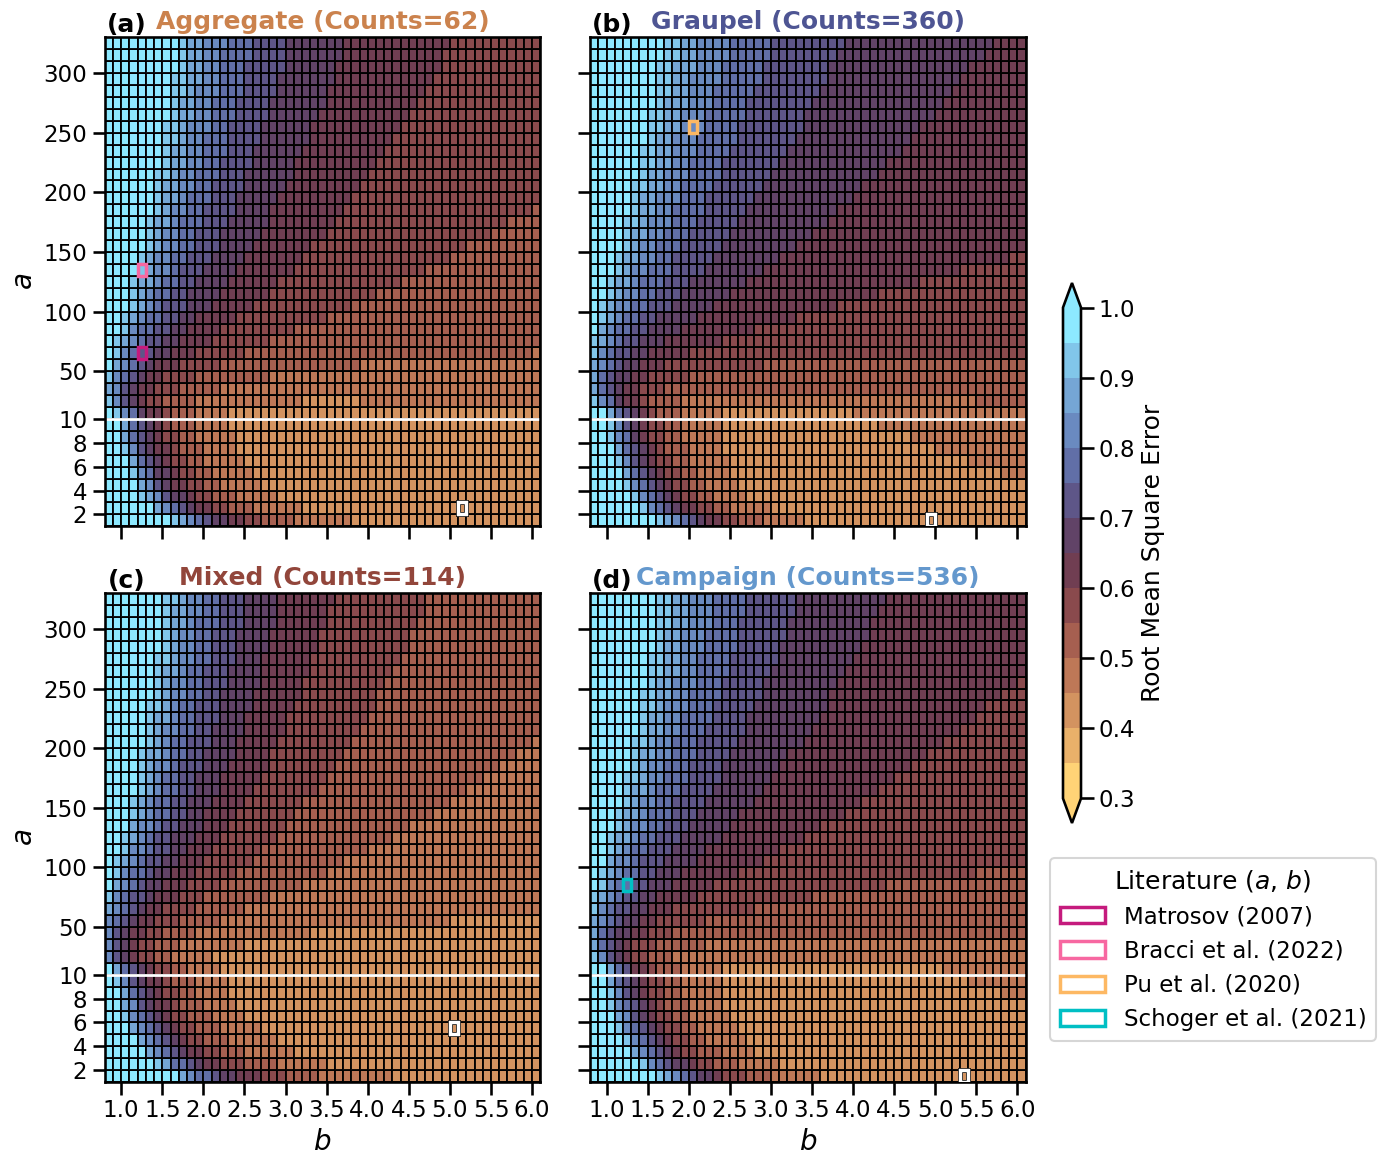

In [25]:
# snowflake classes no precipitation limits
fct.plt_chessboard(df_rmse['snowflake_class'][60], counts['snowflake_class'][60], cbar_label="Root Mean Square Error", category=['aggregate', 'graupel', 'mixed', 'campaign'], vmin=0.3, vmax=1)
plt.savefig(FIG_DIR + "fig08.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

/uio/kant/geo-geofag-u1/franzihe/Documents/Python/oesr_adjust/retrieval_analysis/utils/functions.py:2369: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars


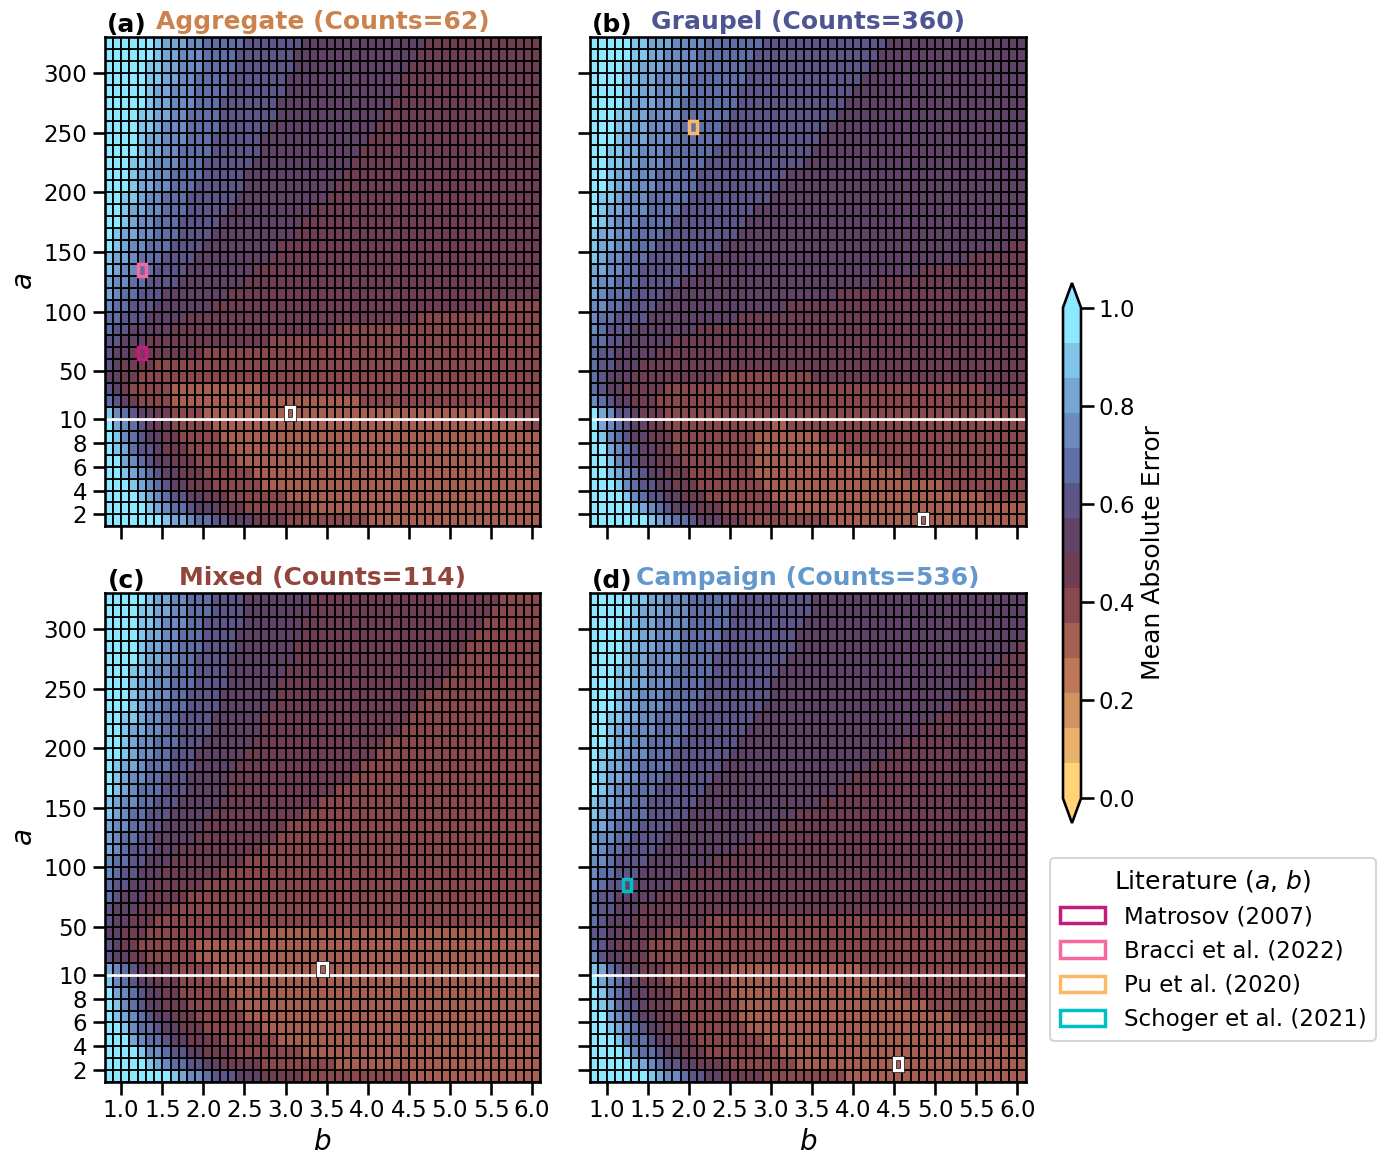

In [26]:
fct.plt_chessboard(df_mae['snowflake_class'][60], counts['snowflake_class'][60], cbar_label="Mean Absolute Error", category=['aggregate', 'graupel', 'mixed', 'campaign'], vmax=1)
plt.savefig(FIG_DIR + "fig08_but_MAE.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

/uio/kant/geo-geofag-u1/franzihe/Documents/Python/oesr_adjust/retrieval_analysis/utils/functions.py:2369: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars


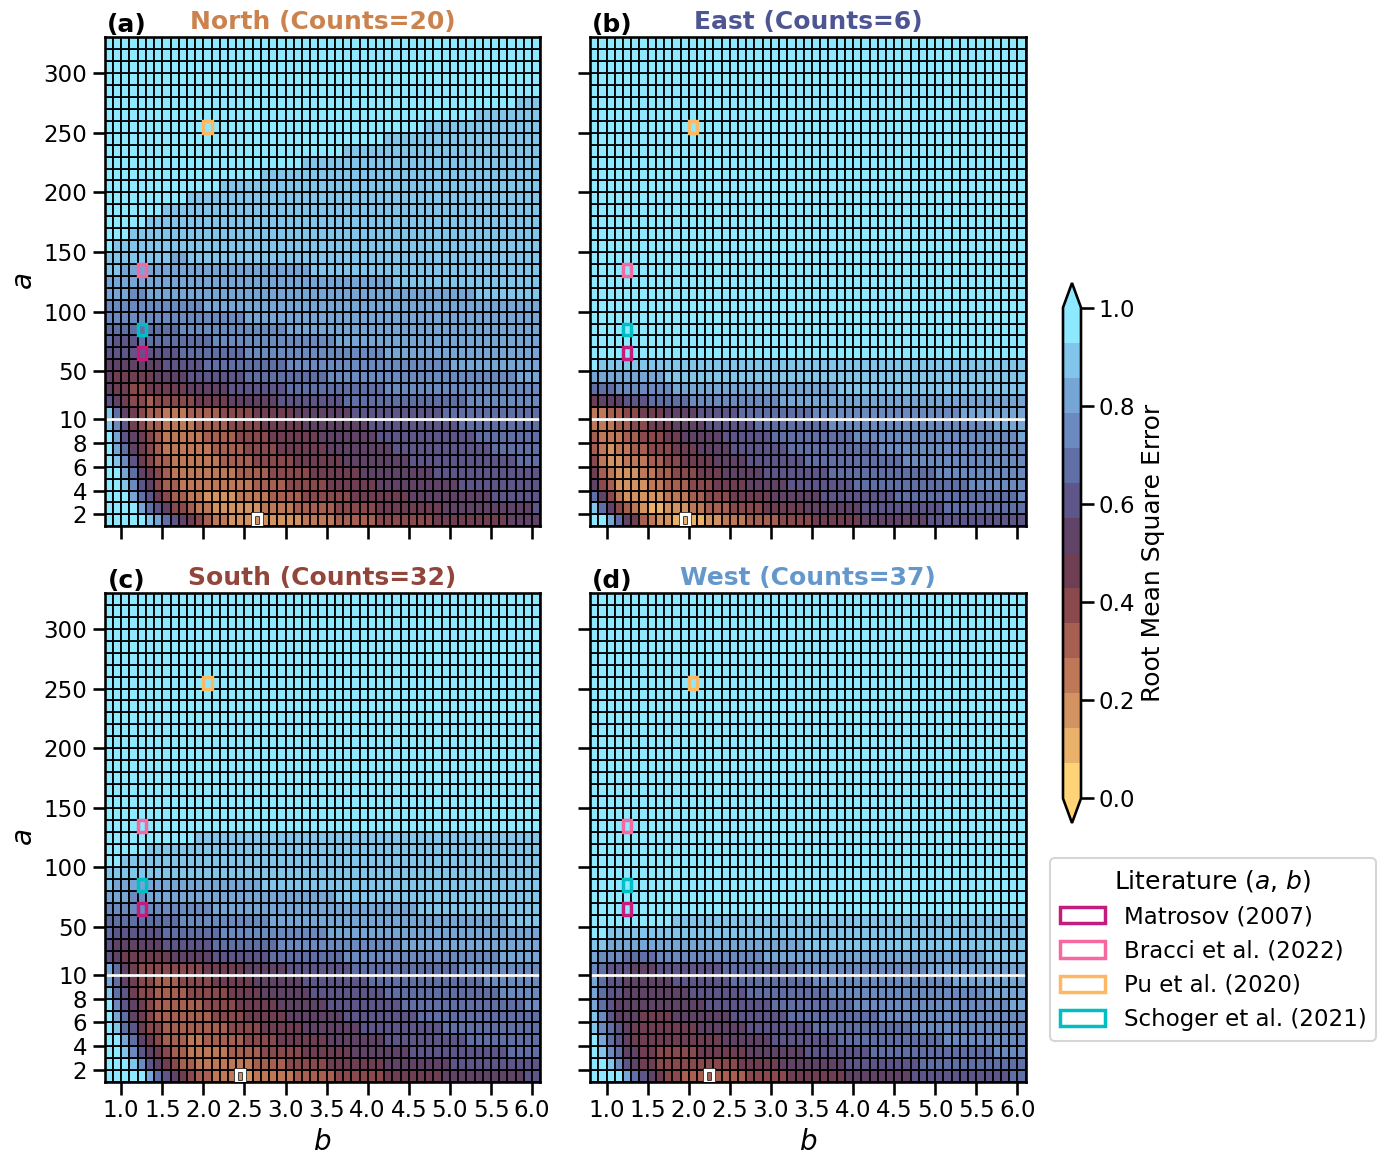

In [27]:
fct.plt_chessboard(df_rmse['high_precipitation'][60], counts['high_precipitation'][60], cbar_label="Root Mean Square Error", category=['North', 'East', 'South', 'West'])

/tmp/ipykernel_1727715/4109819178.py:75: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars


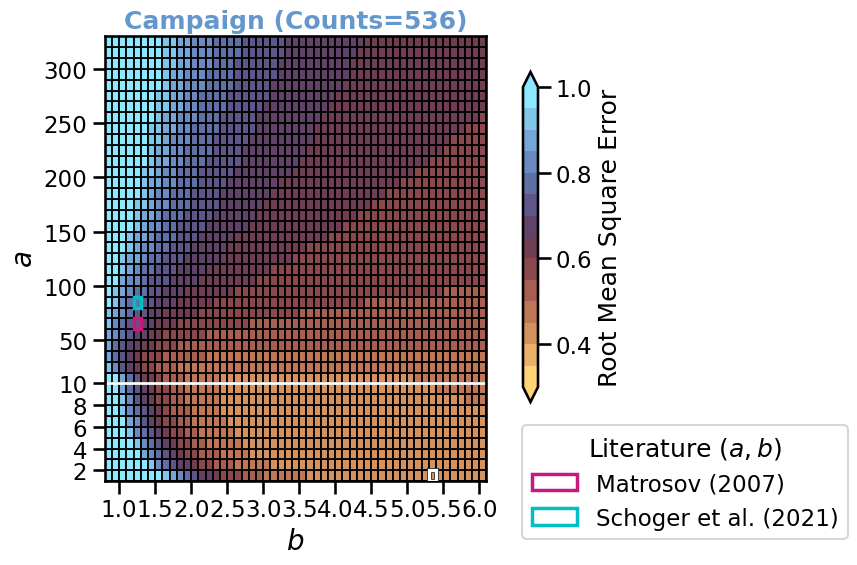

In [28]:
cmap = cm.managua  # define the colormap 
# extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]
# create the new map
custom_cmap2 = LinearSegmentedColormap.from_list(
    'Custom cmap', cmaplist, 14)

wanted_yvals = [2, 4, 6, 8, 10, 50, 100, 150, 200, 250, 300]
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(6,6), sharex=True, sharey=True, constrained_layout=True)
# axs = np.atleast_2d(axs)
a_vals = df_rmse['snowflake_class'][60]['campaign'].index.values
b_vals = df_rmse['snowflake_class'][60]['campaign'].columns.values

x_edges = np.arange(len(b_vals) +1)
y_edges = np.arange(len(a_vals) +1)
c = axs.pcolormesh(x_edges, y_edges, df_rmse['snowflake_class'][60]['campaign'].values, vmin=0.3, vmax=1., 
                      cmap=custom_cmap2,shading="auto", edgecolors=(0, 0, 0, 0.2), linewidth=0.005, alpha=0.9)
# hightlight the cell with minimum RMSE/MAE
iy, ix= np.unravel_index(np.nanargmin(abs(df_rmse['snowflake_class'][60]['campaign'].values)), df_rmse['snowflake_class'][60]['campaign'].shape)
axs.add_patch(Rectangle((ix, iy), 1, 1, # index space
                     fill=False, edgecolor="black", linewidth=3.5, zorder=9))
axs.add_patch(Rectangle((ix,iy), 1, 1,
                     fill=False, edgecolor="white", linewidth=2.5, zorder=10))

# # # Highlight literature boxes
# a_to_idx = {a:i for i,a in enumerate(a_vals)}
# b_to_idx = {b:i for i,b in enumerate(b_vals)}
# # placement = fct.get_lit_placement(['campaign'])
# box = fct.LITERATURE_BOXES["D"]
# fct.draw_lit_box_index(axs, box, a_vals, b_vals)
# # Highlight literature boxes
a_to_idx = {a:i for i,a in enumerate(a_vals)}
b_to_idx = {b:i for i,b in enumerate(b_vals)}
placement = fct.get_lit_placement(['aggregate', 'graupel', 'mixed', 'campaign'])
for study_key in ["A", "D"]:
    box = fct.LITERATURE_BOXES[study_key]
    fct.draw_lit_box_index(axs, box, a_vals, b_vals)

# Ticks & labels
axs.set_title(f"{'campaign'} (counts={counts['snowflake_class'][60]['campaign']})".title(), fontweight='bold', color=fct.custom_colors['campaign'])
# ax.text(0.05, 1.025, fig_label[i], fontweight="bold", horizontalalignment="center", verticalalignment='center', transform = ax.transAxes,color="black")

x_idx = np.arange(2, len(b_vals), 5)
axs.set_xticks(x_idx)
axs.set_xticklabels(b_vals[x_idx])
# a_vals is non-uniform, select by value, map to index
y_idx = [i for i, a in enumerate(a_vals) if a in wanted_yvals]
axs.set_yticks(y_idx)
axs.set_yticklabels(a_vals[y_idx])

split_idx = np.where(a_vals == 10)[0][0]
axs.axhline(split_idx, color='white', lw=2)

axs.set_ylabel(r"$a$", fontsize=20, )#color='white')
axs.set_xlabel(r"$b$", fontsize=20, )#color='white')

lit_handles = [
    Patch(
        facecolor="none",
        edgecolor=fct.LITERATURE_BOXES[key]["color"],
        linewidth=2.5,
        label=fct.LITERATURE_BOXES[key]["label"]
    )
    for key in ["A", "D"]
]

fig.legend(
    handles=lit_handles,
    loc="upper left",
    bbox_to_anchor=(0.88, 0.28),
    frameon=True,
    title=r"Literature $(a,b)$"
)

plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars
cax = fig.add_axes([0.9, 0.3 , 0.025, 0.55]) # left, bottom, width, height
cb = fig.colorbar(c, cax=cax, orientation='vertical', label="Root Mean Square Error" ,spacing="proportional", extend="both")

plt.savefig(FIG_DIR + "fig_rmse_matrosov_schoger.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

## Minimized bias - (a, b) ensemble space


/tmp/ipykernel_1727715/1072177570.py:64: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars


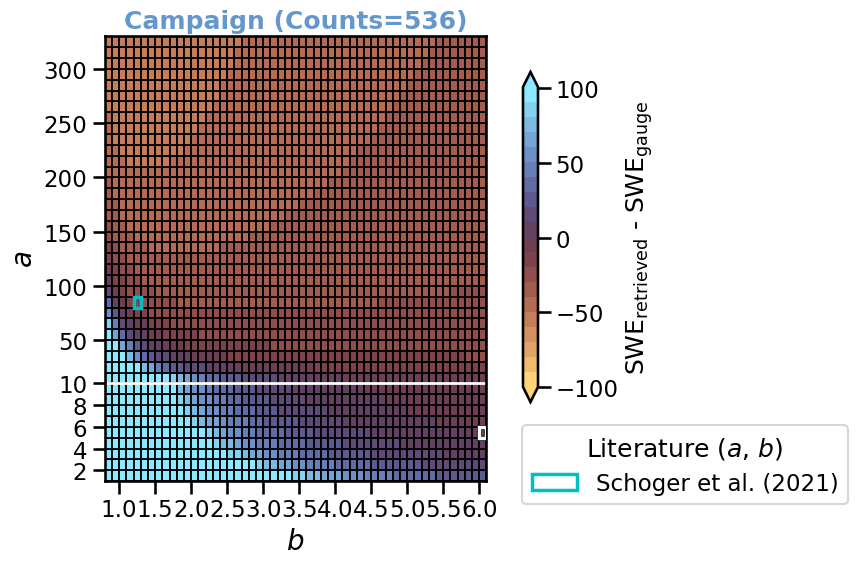

In [29]:
cmap = cm.managua  # define the colormap 
# extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]
# create the new map
custom_cmap2 = LinearSegmentedColormap.from_list(
    'Custom cmap', cmaplist, 20)

wanted_yvals = [2, 4, 6, 8, 10, 50, 100, 150, 200, 250, 300]
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(6,6), sharex=True, sharey=True, constrained_layout=True)
# axs = np.atleast_2d(axs)
a_vals = df_err_cum['snowflake_class'][60]['campaign'].index.values
b_vals = df_err_cum['snowflake_class'][60]['campaign'].columns.values

x_edges = np.arange(len(b_vals) +1)
y_edges = np.arange(len(a_vals) +1)
c = axs.pcolormesh(x_edges, y_edges, df_err_cum['snowflake_class'][60]['campaign'].values, vmin=-100, vmax=101, 
                      cmap=custom_cmap2,shading="auto", edgecolors=(0, 0, 0, 0.2), linewidth=0.005, alpha=0.9)
# hightlight the cell with minimum RMSE/MAE
iy, ix= np.unravel_index(np.nanargmin(abs(df_err_cum['snowflake_class'][60]['campaign'].values)), df_err_cum['snowflake_class'][60]['campaign'].shape)
axs.add_patch(Rectangle((ix, iy), 1, 1, # index space
                     fill=False, edgecolor="black", linewidth=3.5, zorder=9))
axs.add_patch(Rectangle((ix,iy), 1, 1,
                     fill=False, edgecolor="white", linewidth=2.5, zorder=10))

# # Highlight literature boxes
a_to_idx = {a:i for i,a in enumerate(a_vals)}
b_to_idx = {b:i for i,b in enumerate(b_vals)}
# placement = fct.get_lit_placement(['campaign'])
box = fct.LITERATURE_BOXES["D"]
fct.draw_lit_box_index(axs, box, a_vals, b_vals)
# Ticks & labels
axs.set_title(f"{'campaign'} (counts={counts['snowflake_class'][60]['campaign']})".title(), fontweight='bold', color=fct.custom_colors['campaign'])
# ax.text(0.05, 1.025, fig_label[i], fontweight="bold", horizontalalignment="center", verticalalignment='center', transform = ax.transAxes,color="black")

x_idx = np.arange(2, len(b_vals), 5)
axs.set_xticks(x_idx)
axs.set_xticklabels(b_vals[x_idx])
# a_vals is non-uniform, select by value, map to index
y_idx = [i for i, a in enumerate(a_vals) if a in wanted_yvals]
axs.set_yticks(y_idx)
axs.set_yticklabels(a_vals[y_idx])

split_idx = np.where(a_vals == 10)[0][0]
axs.axhline(split_idx, color='white', lw=2)

axs.set_ylabel(r"$a$", fontsize=20, )#color='white')
axs.set_xlabel(r"$b$", fontsize=20, )#color='white')

lit_handles = [
    Patch(facecolor="none",
          edgecolor=box["color"],
          linewidth=2.5,
          label=box["label"])
]

fig.legend(
    handles=lit_handles,
    loc='upper left',
    bbox_to_anchor=(0.88, 0.28),  # tweak this
    frameon=True,
    title=r"Literature ($a$, $b$)"
)

plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars
cax = fig.add_axes([0.9, 0.3 , 0.025, 0.55]) # left, bottom, width, height
cb = fig.colorbar(c, cax=cax, orientation='vertical', label="SWE$_{\mathrm{retrieved}}$ - SWE$_{\mathrm{gauge}}$" ,spacing="proportional", extend="both")

# plt.savefig(FIG_DIR + "figA4.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

## Seasonal/campaign accumulation


In [30]:
rmse_ab = fct.extract_best_ab(df_rmse)
mae_ab = fct.extract_best_ab(df_mae)
err_cum_ab = fct.extract_best_ab(df_err_cum)

In [31]:
snowflake_classes = ['aggregate', 'graupel', 'mixed']
wind_sectors = ['North', 'East', 'South', 'West']
campaign_key = ['campaign']

# -------- Habit (snowflake) configs --------
rmse_cfg = {}

for thresh in thresholds:
    rmse_cfg[thresh] = {}
    # individual snowflake classes

    # All snowflake classes
    rmse_cfg[thresh][f'habit'] = {cls: rmse_ab['snowflake_class'][thresh][cls] 
                                   for cls in snowflake_classes}
    # High precipitation
    rmse_cfg[thresh][f'habit_high_precipitation'] = {cls: rmse_ab['high_precipitation'][thresh][cls] 
                                                      for cls in snowflake_classes}
    # Low precipitation
    rmse_cfg[thresh][f'habit_low_precipitation'] = {cls: rmse_ab['low_precipitation'][thresh][cls] 
                                                     for cls in snowflake_classes}
    # Optional individual snowflake lookup
    for cls in snowflake_classes:
        rmse_cfg[thresh][cls] = {cls: rmse_ab['snowflake_class'][thresh][cls]}  # first threshold as default


In [32]:
# -------- Wind configs --------
wind_rmse_cfg = {}
for thresh in thresholds:
    wind_rmse_cfg[thresh] = {}
    wind_rmse_cfg[thresh][f'wind'] = {sector: rmse_ab['wind_direction_sector'][thresh][sector] 
                                       for sector in wind_sectors}
    wind_rmse_cfg[thresh][f'wind_high_precipitation'] = {sector: rmse_ab['high_precipitation'][thresh][sector] 
                                                          for sector in wind_sectors}
    wind_rmse_cfg[thresh][f'wind_low_precipitation'] = {sector: rmse_ab['low_precipitation'][thresh][sector] 
                                                         for sector in wind_sectors}

In [33]:
# -------- Campaign configs --------
campaign_rmse_cfg = {}
for thresh in thresholds:
    campaign_rmse_cfg[thresh] = {}
    campaign_rmse_cfg[thresh][f'campaign'] = {'campaign': rmse_ab['snowflake_class'][thresh]['campaign']}
    campaign_rmse_cfg[thresh][f'campaign_high_precipitation'] = {'campaign': rmse_ab['high_precipitation'][thresh]['campaign']}
    campaign_rmse_cfg[thresh][f'campaign_low_precipitation'] = {'campaign': rmse_ab['low_precipitation'][thresh]['campaign']}

In [34]:
campaign_err_cum_cfg = {}
for thresh in thresholds:
    campaign_err_cum_cfg[thresh] = {}
    campaign_err_cum_cfg[thresh][f'campaign'] = {'campaign': err_cum_ab['snowflake_class'][thresh]['campaign']}
    campaign_err_cum_cfg[thresh][f'campaign_high_precipitation'] = {'campaign': err_cum_ab['high_precipitation'][thresh]['campaign']}
    campaign_err_cum_cfg[thresh][f'campaign_low_precipitation'] = {'campaign': err_cum_ab['low_precipitation'][thresh]['campaign']}


In [35]:
time_index = sf_class_dict[60]['campaign'].index  

delta_h = sf_class_dict[60]['campaign']['delta_h']
delta_h = delta_h.reindex(time_index)

In [36]:
rmse_series = {}
for thresh, subcfg in rmse_cfg.items():
    rmse_series[thresh] = {}
    for subcat, cfg in subcfg.items():
        rmse_series[thresh][subcat] = fct.build_pp(cfg, sf_class_dict, delta_h, thresh, time_index)
        print(thresh, subcat, rmse_series[thresh][subcat].index.is_unique)   # MUST be True
        print(thresh, subcat, rmse_series[thresh][subcat].isna().sum())      # should be 0



rmse_wind_series = {}
for thresh, subcfg in wind_rmse_cfg.items():
    rmse_wind_series[thresh] = {}
    for subcat, cfg in subcfg.items():
        rmse_wind_series[thresh][subcat] = fct.build_pp(cfg, wd_sector_dict, delta_h, thresh, time_index)
        print(thresh, subcat, rmse_wind_series[thresh][subcat].index.is_unique)   # MUST be True
        print(thresh, subcat, rmse_wind_series[thresh][subcat].isna().sum())  



rmse_campaign_series = {}
for thresh, subcfg in campaign_rmse_cfg.items():
    rmse_campaign_series[thresh] = {}
    for subcat, cfg in subcfg.items():
        rmse_campaign_series[thresh][subcat] = fct.build_pp(cfg, sf_class_dict, delta_h, thresh, time_index)
        print(thresh, subcat, rmse_campaign_series[thresh][subcat].index.is_unique)   # MUST be True
        print(thresh, subcat, rmse_campaign_series[thresh][subcat].isna().sum())  

err_cum_campaign_series = {}
for thresh, subcfg in campaign_err_cum_cfg.items():
    err_cum_campaign_series[thresh] = {}
    for subcat, cfg in subcfg.items():
        err_cum_campaign_series[thresh][subcat] = fct.build_pp(cfg, sf_class_dict, delta_h, thresh, time_index)
        print(thresh, subcat, err_cum_campaign_series[thresh][subcat].index.is_unique)   # MUST be True
        print(thresh, subcat, err_cum_campaign_series[thresh][subcat].isna().sum())  

60 habit True
60 habit 0
60 habit_high_precipitation True
60 habit_high_precipitation 0
60 habit_low_precipitation True
60 habit_low_precipitation 0
60 aggregate True
60 aggregate 474
60 graupel True
60 graupel 176
60 mixed True
60 mixed 422
70 habit True
70 habit 0
70 habit_high_precipitation True
70 habit_high_precipitation 0
70 habit_low_precipitation True
70 habit_low_precipitation 0
70 aggregate True
70 aggregate 499
70 graupel True
70 graupel 242
70 mixed True
70 mixed 331
80 habit True
80 habit 0
80 habit_high_precipitation True
80 habit_high_precipitation 0
80 habit_low_precipitation True
80 habit_low_precipitation 0
80 aggregate True
80 aggregate 513
80 graupel True
80 graupel 296
80 mixed True
80 mixed 263
60 wind True
60 wind 0
60 wind_high_precipitation True
60 wind_high_precipitation 0
60 wind_low_precipitation True
60 wind_low_precipitation 0
70 wind True
70 wind 0
70 wind_high_precipitation True
70 wind_high_precipitation 0
70 wind_low_precipitation True
70 wind_low_prec

In [37]:
df_rmse['snowflake_class'][60].keys()

dict_keys(['aggregate', 'graupel', 'mixed', 'campaign'])

In [38]:
for clse, (a, b) in rmse_cfg[80]['habit'].items():
    key = f"S_{a}_{b}_400_mm_h"
    s = sf_class_dict[80][clse][key]
    _rmse = df_rmse['snowflake_class'][80][clse].loc[a, b]
    _pe = (len(s)/len(sf_class_dict[80]['campaign'].index))*100
    print(clse, a, b,_rmse.round(4), len(s),  round(_pe,1))

aggregate 3 4.0 0.415 23 4.3
graupel 1 4.8 0.4046 240 44.8
mixed 4 4.2 0.4136 273 50.9


In [39]:
round(_pe, 1)

50.9

In [40]:
df_rmse['snowflake_class'][80]['campaign'].loc[campaign_err_cum_cfg[60]['campaign']['campaign']].round(4)

np.float64(0.4401)

In [41]:
for clse, (a, b) in wind_rmse_cfg[60]['wind'].items():
    key = f"S_{a}_{b}_400_mm_h"
    s = wd_sector_dict[60][clse][key]
    _rmse = df_rmse['wind_direction_sector'][60][clse].loc[a, b]
    _pe = (len(s)/len(sf_class_dict[60]['campaign'].index))*100
    print(clse, a, b,_rmse.round(4), len(s),  round(_pe,1))

North 2 4.1 0.3815 88 16.4
East 2 2.8 0.317 28 5.2
South 5 4.3 0.3965 247 46.1
West 1 4.8 0.442 173 32.3


In [42]:
day_start = sf_class_dict[60]['campaign'].index.min().normalize()
day_end = sf_class_dict[60]['campaign'].index.max().normalize() + pd.Timedelta('1D')
ds_season = ds_23.sel(time=slice(day_start, day_end))
# get the “no MASC available” timestamps
all_times = ds_23['time'].values
masc_times = sf_class_dict[60]['campaign'].index
# threshold one day

# Step 1: sort (just to be safe)
masc_times = masc_times.sort_values()
masc_series = masc_times.to_series()

# Step 2: compute the gaps between consecutive MASC timesteps
deltat = masc_series.diff()
# mask for large gaps # threshold one day
gap_mask = deltat > pd.Timedelta('1440min')

# Step 3: find where the gap exceeds threshold
# gap_starts = masc_times[deltat > threshold] # first timestamp *after* a long gap
gap_ends = masc_series[gap_mask]

# gap_ends = gap_starts - deltat[deltat > threshold] # last timestamp *before* the gap
gap_starts = masc_series.shift(1)[gap_mask]

gaps = list(zip(gap_starts.values, gap_ends.values))
gaps = [
    (start, end)
    for start, end in zip(gap_starts, gap_ends)
    if pd.notna(start) and pd.notna(end)
]

In [43]:
for g0, g1 in gaps:
    print(g0, "→", g1, "| Δt =", g1 - g0)

2023-02-19 10:25:00 → 2023-02-21 04:08:00 | Δt = 1 days 17:43:00
2023-02-21 06:25:00 → 2023-02-23 03:37:00 | Δt = 1 days 21:12:00
2023-02-25 10:46:00 → 2023-03-01 22:48:00 | Δt = 4 days 12:02:00
2023-03-06 23:17:00 → 2023-03-08 14:54:00 | Δt = 1 days 15:37:00


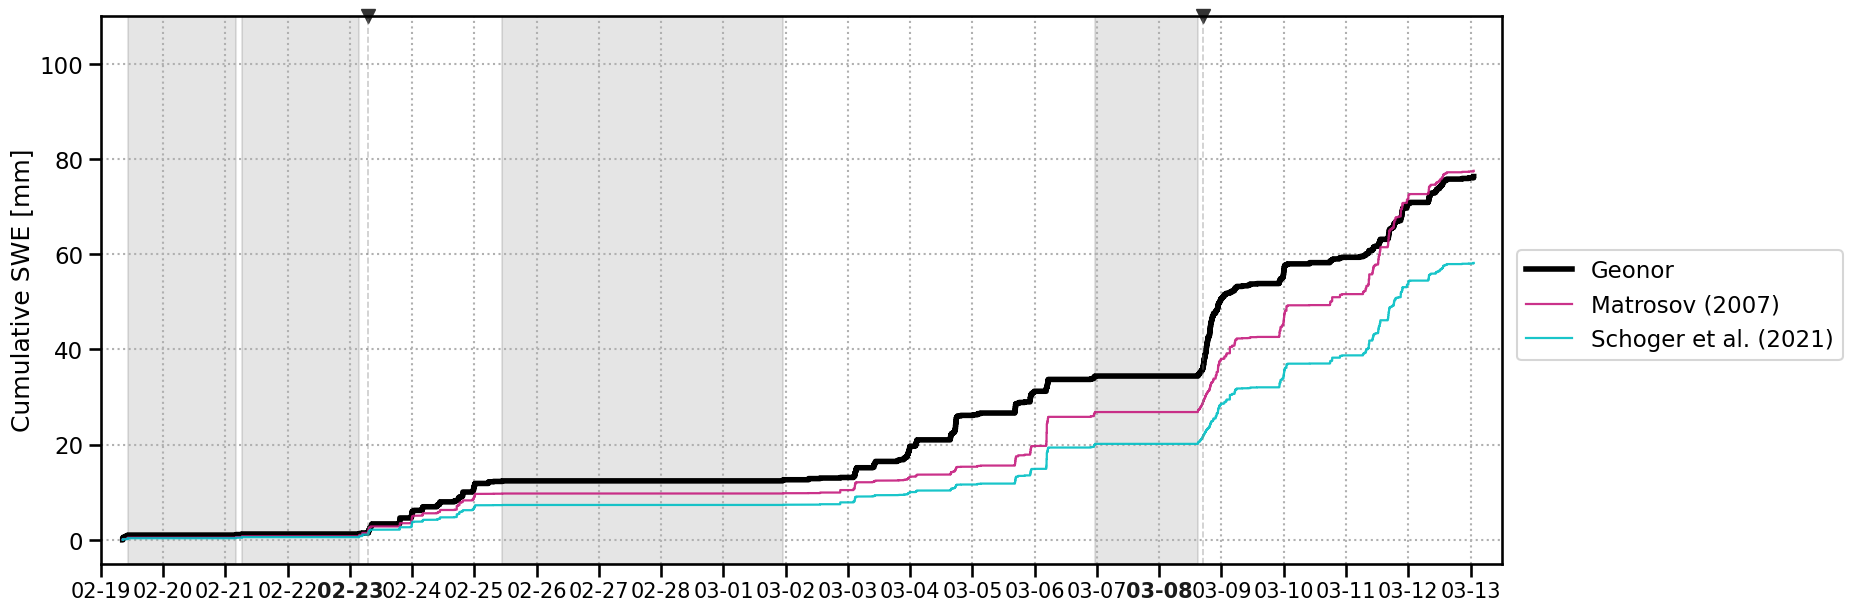

In [44]:
case_dates = [
    pd.Timestamp("2023-02-23 07:00"),
    pd.Timestamp("2023-03-08 17:00"),
    # pd.Timestamp("2023-03-11"),
]

case_dates_num = fct.date2num(case_dates)
case_dates_str = [d.strftime("%m-%d") for d in case_dates]

handles = []
labels = []

fig, ax = plt.subplots(1, 1, figsize=(15,6), sharex=True, sharey=True, constrained_layout=True)

custom_cmap = LinearSegmentedColormap.from_list(
'Custom cmap', cmaplist, 8)

# for ax in axs.flatten():
rate = sf_class_dict[60]['campaign']['rate_mm_h']
rate = rate.reindex(time_index).fillna(0)
fct.plt_cum(ax, rate*delta_h, time_index, "Geonor", "k", "-", 4)

rate = sf_class_dict[60]['campaign']['Matrosov_aggregate_400_mm_h']
rate = rate.reindex(time_index).fillna(0)
fct.plt_cum(ax, rate*delta_h, time_index, fct.LITERATURE_BOXES["A"]['label'], fct.LITERATURE_BOXES["A"]["color"], "-", 1.6, alpha=.9)

# rate = sf_class_dict[60]['campaign']['Bracci_aggregate_400_mm_h']
# rate = rate.reindex(time_index).fillna(0)
# fct.plt_cum(ax, rate*delta_h, time_index, fct.LITERATURE_BOXES["B"]['label'], fct.LITERATURE_BOXES["B"]["color"], "-", 1.6, alpha=.9)

# rate = sf_class_dict[60]['campaign']['Pu_graupel_400_mm_h']
# rate = rate.reindex(time_index).fillna(0)
# fct.plt_cum(ax, rate*delta_h, time_index, fct.LITERATURE_BOXES["C"]['label'], fct.LITERATURE_BOXES["C"]["color"], "-", 1.6, alpha=.9)

rate = sf_class_dict[60]['campaign']['Schoger_400_mm_h']
rate = rate.reindex(time_index).fillna(0)
fct.plt_cum(ax, rate*delta_h, time_index, fct.LITERATURE_BOXES["D"]['label'], fct.LITERATURE_BOXES["D"]["color"], "-", 1.6, alpha=.9)

# hightlight the MASC gaps
for g_start, g_end in gaps:
    g_start = fct.date2num(g_start)
    g_end = fct.date2num(g_end)
    ax.axvspan(g_start, g_end, color='k', alpha=0.1)

# styles = [
#     ("habit", "--"),
#     # ("habit_high_precipitation", "-."),
#     # ("habit_low_precipitation", ":") 
# ]
# for i, (name, ls) in enumerate(styles):
#     fct.plt_cum(ax, rmse_series[60][name], time_index, name.replace("_", " ").title(), custom_cmap(i), ls, 3)
# #     fct.plt_cum(axs[1], mae_series[60][name], name.replace("_", " ").title(), custom_cmap(i), ls, 3)

# wind_styles = [
#     ("wind", "--"),
#     # ("wind_high_precipitation", "-."),
#     # ("wind_low_precipitation", ":") 
# ]
# for i, (name, ls) in enumerate(wind_styles, start=3):
#     fct.plt_cum(ax, rmse_wind_series[60][name], time_index, name.replace("_", " ").title(), custom_cmap(i), ls, 3)
# #     fct.plt_cum(axs[1], mae_wind_series[60][name], name.replace("_", " ").title(), custom_cmap(i), ls, 3)

# campaign_styles = [
#     ("campaign", "--"),
#     # ("campaign_high_precipitation", "-."),
#     # ("campaign_low_precipitation", ":") 
# ]
# for i, (name, ls) in enumerate(campaign_styles, start=6):
#     fct.plt_cum(ax, rmse_campaign_series[60][name], time_index, name.replace("_", " ").title(), custom_cmap(i), ls, 3)
# #     fct.plt_cum(axs[1], mae_campaign_series[60][name], name.replace("_", " ").title(), custom_cmap(i), ls, 3)

# fct.plt_cum(ax, err_cum_campaign_series[60]["campaign"], time_index, f"Campaign (minimized biase)", custom_cmap(6), ":", 3)

# ------ formatting ----
major_locator = DayLocator(interval=1)   # label every 2 days 
date_form = DateFormatter("%m-%d")       # no year
precip_event = 'campaign'
# ax.set_title(precip_event.title(), fontweight="bold", color=fct.custom_colors[precip_event])
# ax.text(0.025, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)

ax.xaxis.set_major_locator(major_locator)
ax.xaxis.set_major_formatter(date_form)

ax.grid(which='major', axis='x', linestyle=':')
ax.grid(which='minor', axis='x', linestyle=':', alpha=0.3)

ax.grid(which='major', axis='y', linestyle=':')
# ax.grid(which='minor', axis='y', linestyle=':', alpha=0.3)

ax.tick_params(axis="x", labelrotation=0)
plt.setp(ax.get_xticklabels(), horizontalalignment='center')

    
ax.set_xlim([pd.Timestamp("2023-02-19 00:00:00"), pd.Timestamp("2023-03-13 12:00:00")])
# ax.set_xlim([pd.Timestamp("2023-02-19"), pd.Timestamp("2023-02-22")])
ylim = [-5, 110]
ax.set_ylim(ylim)
    
ax.set_ylabel("Cumulative SWE [mm]")
h, l = ax.get_legend_handles_labels()
handles.extend(h)
labels.extend(l)

ax.tick_params(which='minor', length=3)
ylim = ax.get_ylim()
        
for x in case_dates_num:
    ax.plot(x, ylim[1], marker='v', color='0.2', markersize=10, clip_on=False)
    ax.axvline(x, color='0.5', linestyle='--', alpha=0.4, linewidth=1.2)


for label in ax.get_xticklabels():
    label.set_fontsize(15)
    if label.get_text() in case_dates_str:
            label.set_color('0.1')
            label.set_fontweight('bold')
            label.set_fontsize(15)



unique = dict(zip(labels, handles))
fig.legend(unique.values(), unique.keys(), loc='center left', bbox_to_anchor=(1, 0.5))   
# plt.tight_layout(rect=[0, 0, 0., 1])   # leave room for cbars

plt.savefig(FIG_DIR + "fig07a_presentation_literature.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

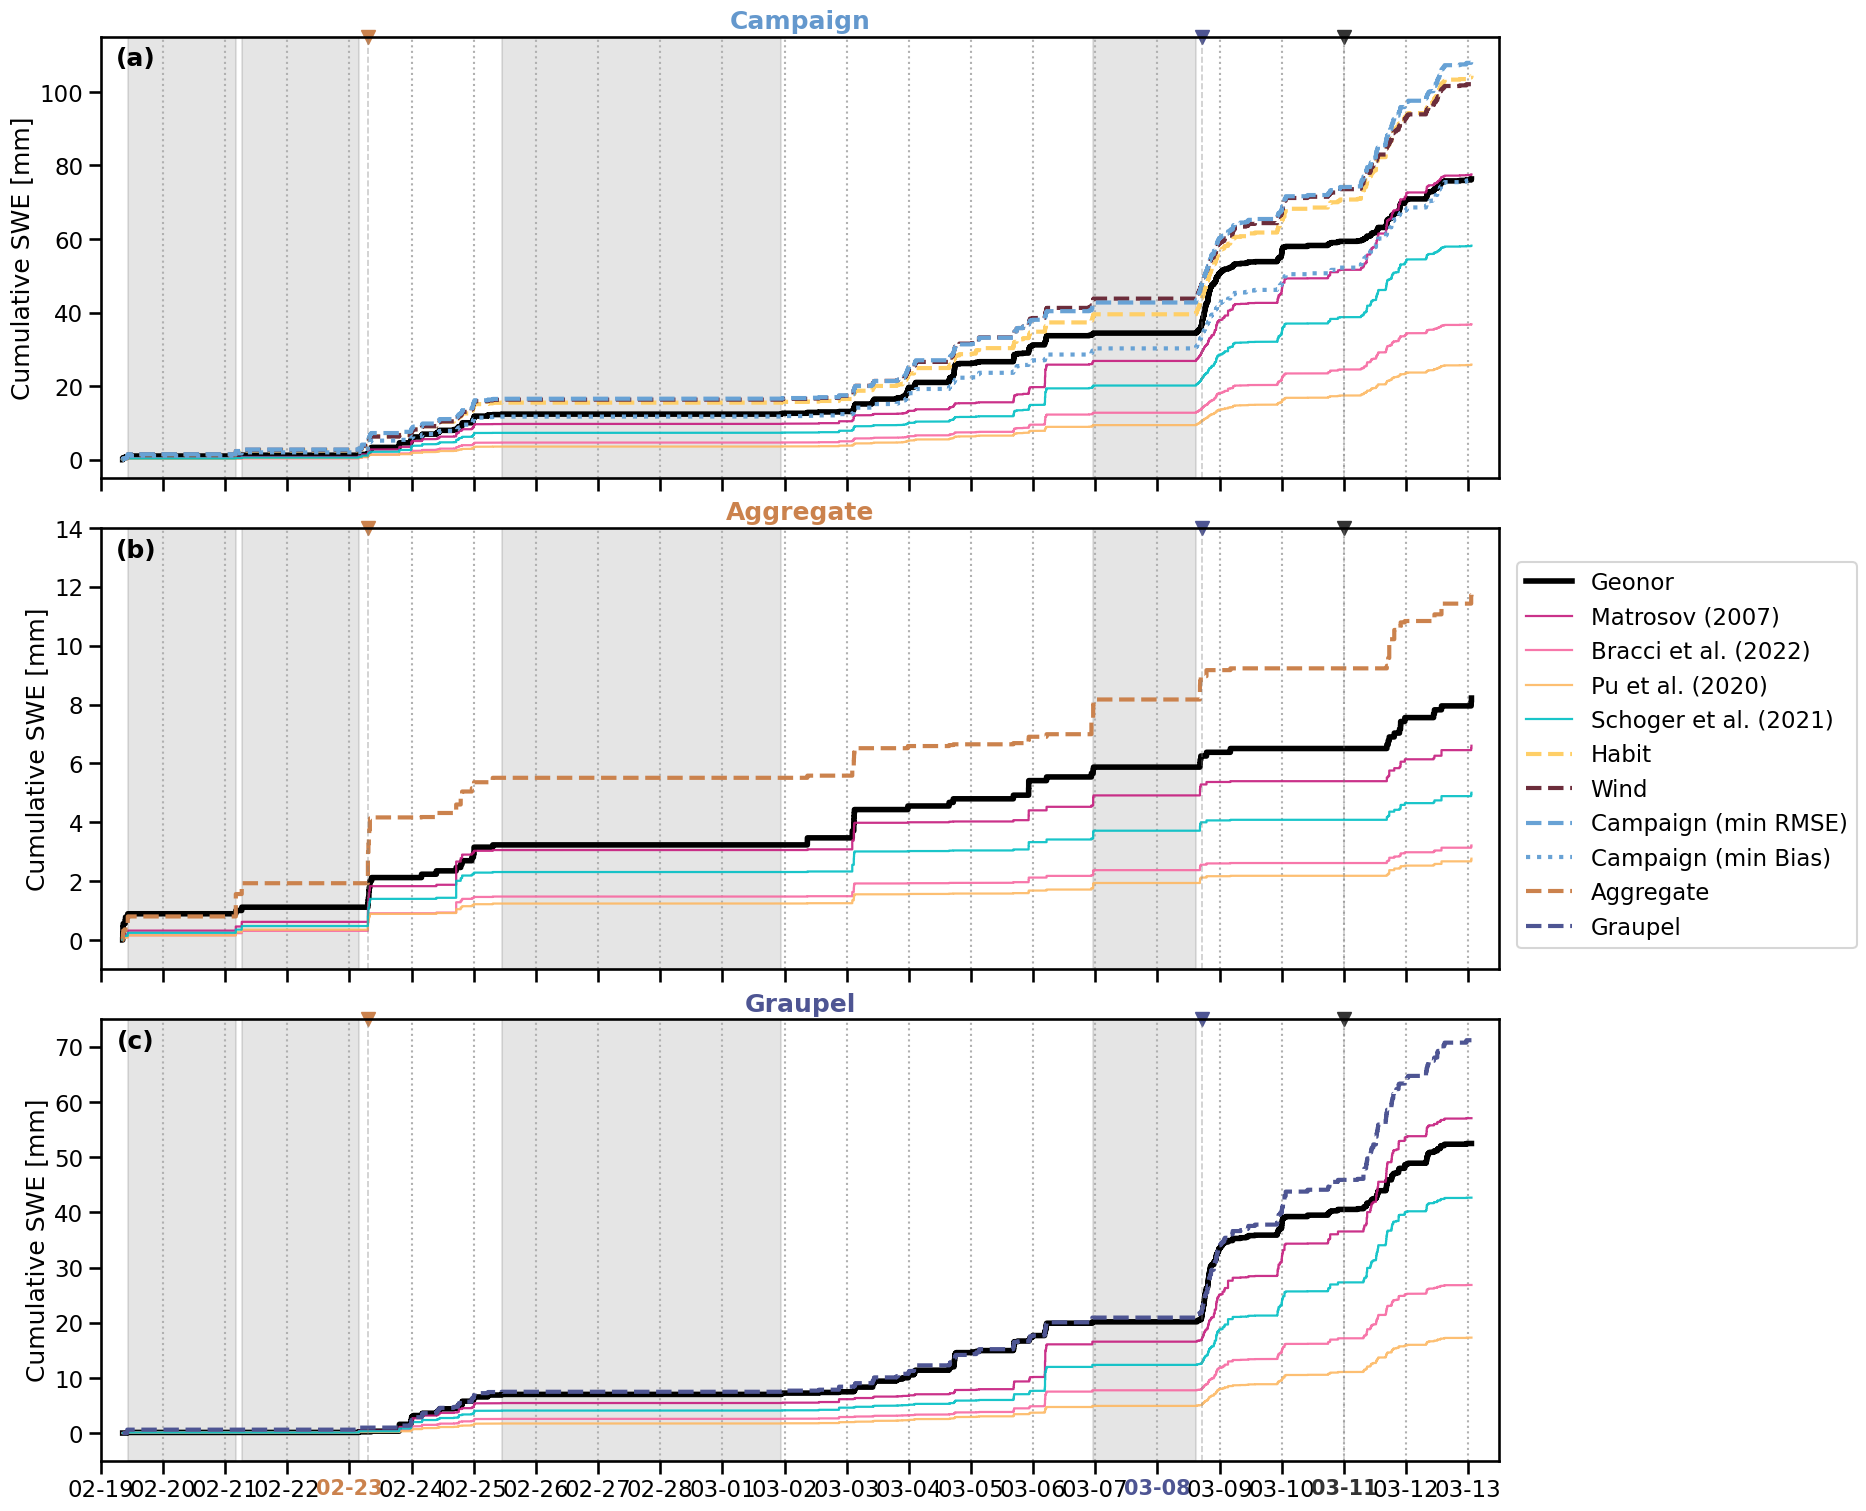

In [45]:
threshold =  60
# Define your case study dates
case_dates = [
    pd.Timestamp("2023-02-23 07:00"),
    pd.Timestamp("2023-03-08 17:00"),
    pd.Timestamp("2023-03-11"),
]

case_dates_num = fct.date2num(case_dates)
case_dates_str = [d.strftime("%m-%d") for d in case_dates]
case_colors = [
    fct.custom_colors['aggregate'],
    fct.custom_colors['graupel'],
    '0.2'
]
date_color_map = dict(zip(case_dates_str, case_colors))




fig, axs = plt.subplots(3, 1, figsize=(15,15), sharex=True, #sharey=True, 
                        constrained_layout=True)
handles = []
labels = []
custom_cmap = LinearSegmentedColormap.from_list(
'Custom cmap', cmaplist, 8)

for (i,ax), precip_event in zip(enumerate(axs.flatten()), ['campaign', 'aggregate', 'graupel']):
    rate = sf_class_dict[threshold][precip_event]['rate_mm_h']
    rate = rate.reindex(time_index).fillna(0)
    fct.plt_cum(ax, rate*delta_h, time_index, "Geonor", "k", "-", 4)

    rate = sf_class_dict[threshold][precip_event]['Matrosov_aggregate_400_mm_h']
    rate = rate.reindex(time_index).fillna(0)
    fct.plt_cum(ax, rate*delta_h, time_index, fct.LITERATURE_BOXES["A"]['label'], fct.LITERATURE_BOXES["A"]["color"], "-", 1.6, alpha=.9)

    rate = sf_class_dict[threshold][precip_event]['Bracci_aggregate_400_mm_h']
    rate = rate.reindex(time_index).fillna(0)
    fct.plt_cum(ax, rate*delta_h, time_index, fct.LITERATURE_BOXES["B"]['label'], fct.LITERATURE_BOXES["B"]["color"], "-", 1.6, alpha=.9)

    rate = sf_class_dict[threshold][precip_event]['Pu_graupel_400_mm_h']
    rate = rate.reindex(time_index).fillna(0)
    fct.plt_cum(ax, rate*delta_h, time_index, fct.LITERATURE_BOXES["C"]['label'], fct.LITERATURE_BOXES["C"]["color"], "-", 1.6, alpha=.9)

    rate = sf_class_dict[threshold][precip_event]['Schoger_400_mm_h']
    rate = rate.reindex(time_index).fillna(0)
    fct.plt_cum(ax, rate*delta_h, time_index, fct.LITERATURE_BOXES["D"]['label'], fct.LITERATURE_BOXES["D"]["color"], "-", 1.6, alpha=.9)

    # hightlight the MASC gaps
    for g_start, g_end in gaps:
        g_start = fct.date2num(g_start)
        g_end = fct.date2num(g_end)
        ax.axvspan(g_start, g_end, color='k', alpha=0.1)
    if precip_event == "aggregate" or precip_event == "graupel":
        fct.plt_cum(ax, rmse_series[threshold][precip_event], time_index, precip_event.replace("_", " ").title(), fct.custom_colors[precip_event], "--", 3)
    
        
    if precip_event == "campaign":
        fct.plt_cum(ax, rmse_series[threshold]["habit"], time_index, "Habit", custom_cmap(0), "--", 3)

        fct.plt_cum(ax, rmse_wind_series[threshold]["wind"], time_index, "Wind", custom_cmap(3), "--", 3)

        fct.plt_cum(ax, rmse_campaign_series[threshold]["campaign"], time_index, f"Campaign (min RMSE)", custom_cmap(6), "--", 3)

        fct.plt_cum(ax, err_cum_campaign_series[threshold]["campaign"], time_index, f"Campaign (min Bias)", custom_cmap(6), ":", 3)

    
    # ------ formatting ----
    major_locator = DayLocator(interval=1)   # label every 2 days 
    # minor_locator = DayLocator(interval=1)   # tick every day
    date_form = DateFormatter("%m-%d")       # no year

    ax.set_title(precip_event.title(), fontweight="bold", color=fct.custom_colors[precip_event])
    ax.text(0.025, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)

    ax.xaxis.set_major_locator(major_locator)
    # ax.xaxis.set_minor_locator(minor_locator)
    ax.xaxis.set_major_formatter(date_form)

    # ax.xaxis.grid(which="both", ls=":")
    # ax.yaxis.grid(which="both", ls=":")
    ax.grid(which='major', axis='x', linestyle=':')
    ax.grid(which='minor', axis='x', linestyle=':', alpha=0.3)

    ax.tick_params(axis="x", labelrotation=0)
    plt.setp(ax.get_xticklabels(), horizontalalignment='center')

    # ax.xaxis_date()
    ax.set_xlim([pd.Timestamp("'2023-02-19' 00:00:00"), pd.Timestamp(f"'2023-03-13' 12:00:00")])
    if i == 0: 
        ylim = [-5, 115]
    if i == 1:
        ylim = [-1, 14]
    if i == 2:
        ylim = [-5, 75]
    ax.set_ylim(ylim)
    
    ax.set_ylabel("Cumulative SWE [mm]")
    # ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

    ax.tick_params(which='minor', length=3)
    ylim = ax.get_ylim()
        
    # for x in case_dates_num:
    #     ax.plot(x, ylim[1], marker='v', color='0.2', markersize=10, clip_on=False)
    #     ax.axvline(x, color='0.5', linestyle='--', alpha=0.4, linewidth=1.2)
    for x, color in zip(case_dates_num, case_colors):
        ax.plot(x, ylim[1], marker='v', color=color, markersize=10, clip_on=False)
        ax.axvline(x, color='0.5', linestyle='--', alpha=0.4, linewidth=1.2)


    # for label in ax.get_xticklabels():
    #     if label.get_text() in case_dates_str:
    #         label.set_color('0.1')
    #         label.set_fontweight('bold')
    #         label.set_fontsize(15)
    for label in ax.get_xticklabels():
        txt = label.get_text()
        if txt in date_color_map:
            label.set_color(date_color_map[txt])
            label.set_fontweight('bold')
            label.set_fontsize(15)



unique = dict(zip(labels, handles))
fig.legend(unique.values(), unique.keys(), loc='center left', bbox_to_anchor=(1, 0.5))    
# plt.tight_layout(rect=[0, 0, 0., 1])   # leave room for cbars
# fig.subplots_adjust(right=0.8)
plt.savefig(FIG_DIR + f"fig07_{threshold}.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

In [46]:
precip_event = 'campaign'
rate = sf_class_dict[threshold][precip_event]['rate_mm_h']
rate = rate.reindex(time_index).fillna(0)
series = rate*delta_h
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_obs = s.cumsum()
cum_obs = cum_obs - cum_obs.iloc[0]
len(cum_obs), cum_obs[-1].round(1)

(536, np.float64(76.3))

In [47]:
rate = sf_class_dict[threshold][precip_event]['Matrosov_aggregate_400_mm_h']
rate = rate.reindex(time_index).fillna(0)
series = rate*delta_h
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(77.5), np.float64(1.6))

In [48]:
rate = sf_class_dict[threshold][precip_event]['Bracci_aggregate_400_mm_h']
rate = rate.reindex(time_index).fillna(0)
series = rate*delta_h
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(36.8), np.float64(-51.8))

In [49]:
rate = sf_class_dict[threshold][precip_event]['Pu_graupel_400_mm_h']
rate = rate.reindex(time_index).fillna(0)
series = rate*delta_h
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(25.8), np.float64(-66.2))

In [50]:
rate = sf_class_dict[threshold][precip_event]['Schoger_400_mm_h']
rate = rate.reindex(time_index).fillna(0)
series = rate*delta_h
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(58.2), np.float64(-23.8))

In [51]:
series = rmse_campaign_series[threshold]["campaign"]
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(108.4), np.float64(42.0))

In [52]:
series = err_cum_campaign_series[threshold]["campaign"]
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(76.3), np.float64(-0.1))

In [53]:
series = rmse_series[60]["habit"]
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(104.4), np.float64(36.8))

In [54]:
series = rmse_series[70]["habit"]
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(104.0), np.float64(36.3))

In [55]:
series = rmse_series[80]["habit"]
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(103.1), np.float64(35.1))

In [56]:
series = rmse_wind_series[threshold]["wind"]
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(102.5), np.float64(34.3))

In [57]:
rate = sf_class_dict[threshold]['graupel']['rate_mm_h']
rate = rate.reindex(time_index).fillna(0)
series = rate*delta_h
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_obs = s.cumsum()
cum_obs = cum_obs - cum_obs.iloc[0]
len(cum_obs), cum_obs[-1].round(1)

rate = sf_class_dict[threshold]['graupel']['Pu_graupel_400_mm_h']
rate = rate.reindex(time_index).fillna(0)
series = rate*delta_h
s = series.reindex(time_index)
s = s.fillna(0)   # correct for rates / increments
cum_ret = s.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(17.3), np.float64(-67.0))

In [58]:
# dynamic text color
def get_text_color(color):
    r, g, b = to_rgb(color)
    luminance = 0.299*r + 0.587*g + 0.114*b
    return 'black' if luminance > 0.6 else 'white'

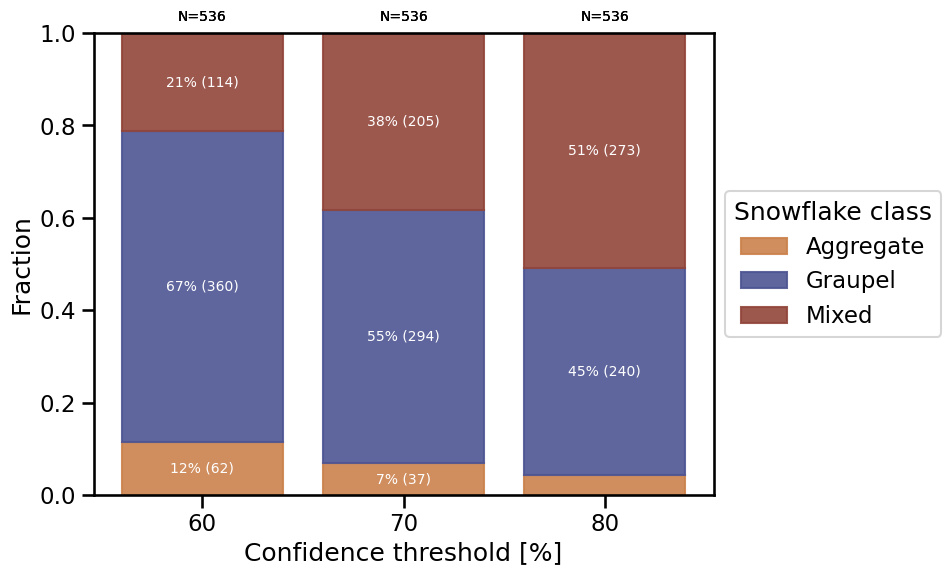

In [59]:
order = ['aggregate', 'graupel', 'mixed']

# collect counts
counts2 = {name: [] for name in order}

for thresh in thresholds:
    for name in order:
        key = f"{name}_{thresh}"
        habit = sf_class_dict[thresh][name][f'snowflake_class_name_{thresh}']
        counts2[name].append(len(habit))
# totals per threshold
totals = np.sum([counts2[n] for n in order], axis=0)

# ---- plotting ----
fig, ax = plt.subplots(figsize=(8,6))

x = np.arange(len(thresholds))
bottom = np.zeros(len(thresholds))

for name in order:
    raw_vals = np.array(counts2[name])
    frac_vals = raw_vals / totals
    # totals = np.sum([counts[n] for n in order], axis=0)
    # values = np.array(counts[name]) / totals
    ax.bar(
        x,
        frac_vals,
        bottom=bottom,
        label=name.title(),
        color=fct.custom_colors[name],
        edgecolor=fct.custom_colors[name],
        alpha = 0.9
    )
    # ---- annotations ----
    for i in range(len(x)):
        height = frac_vals[i]
        count = raw_vals[i]
        perc = height * 100

        # skip very small segments (avoid clutter)
        if height < 0.05:
            continue

        ax.text(
            x[i],
            bottom[i] + height / 2,
            f"{perc:.0f}% ({count})",
            ha='center',
            va='center',
            fontsize=10,
            color=get_text_color(fct.custom_colors[name])  # or 'black' depending on contrast
        )
    bottom += frac_vals
    for i, total in enumerate(totals):
        ax.text(x[i], 1.02, f"N={total}", ha='center', va='bottom', fontsize=10)

ax.set_xlabel("Confidence threshold [%]")
ax.set_ylabel("Fraction")
ax.set_xticks(x)
ax.set_xticklabels(thresholds)
ax.set_ylim(0,1)
ax.legend(title="Snowflake class", loc='center left', bbox_to_anchor=(1, 0.5))


# plt.savefig(FIG_DIR + "figA3.png", format='png', bbox_inches='tight', transparent=True,dpi=300)


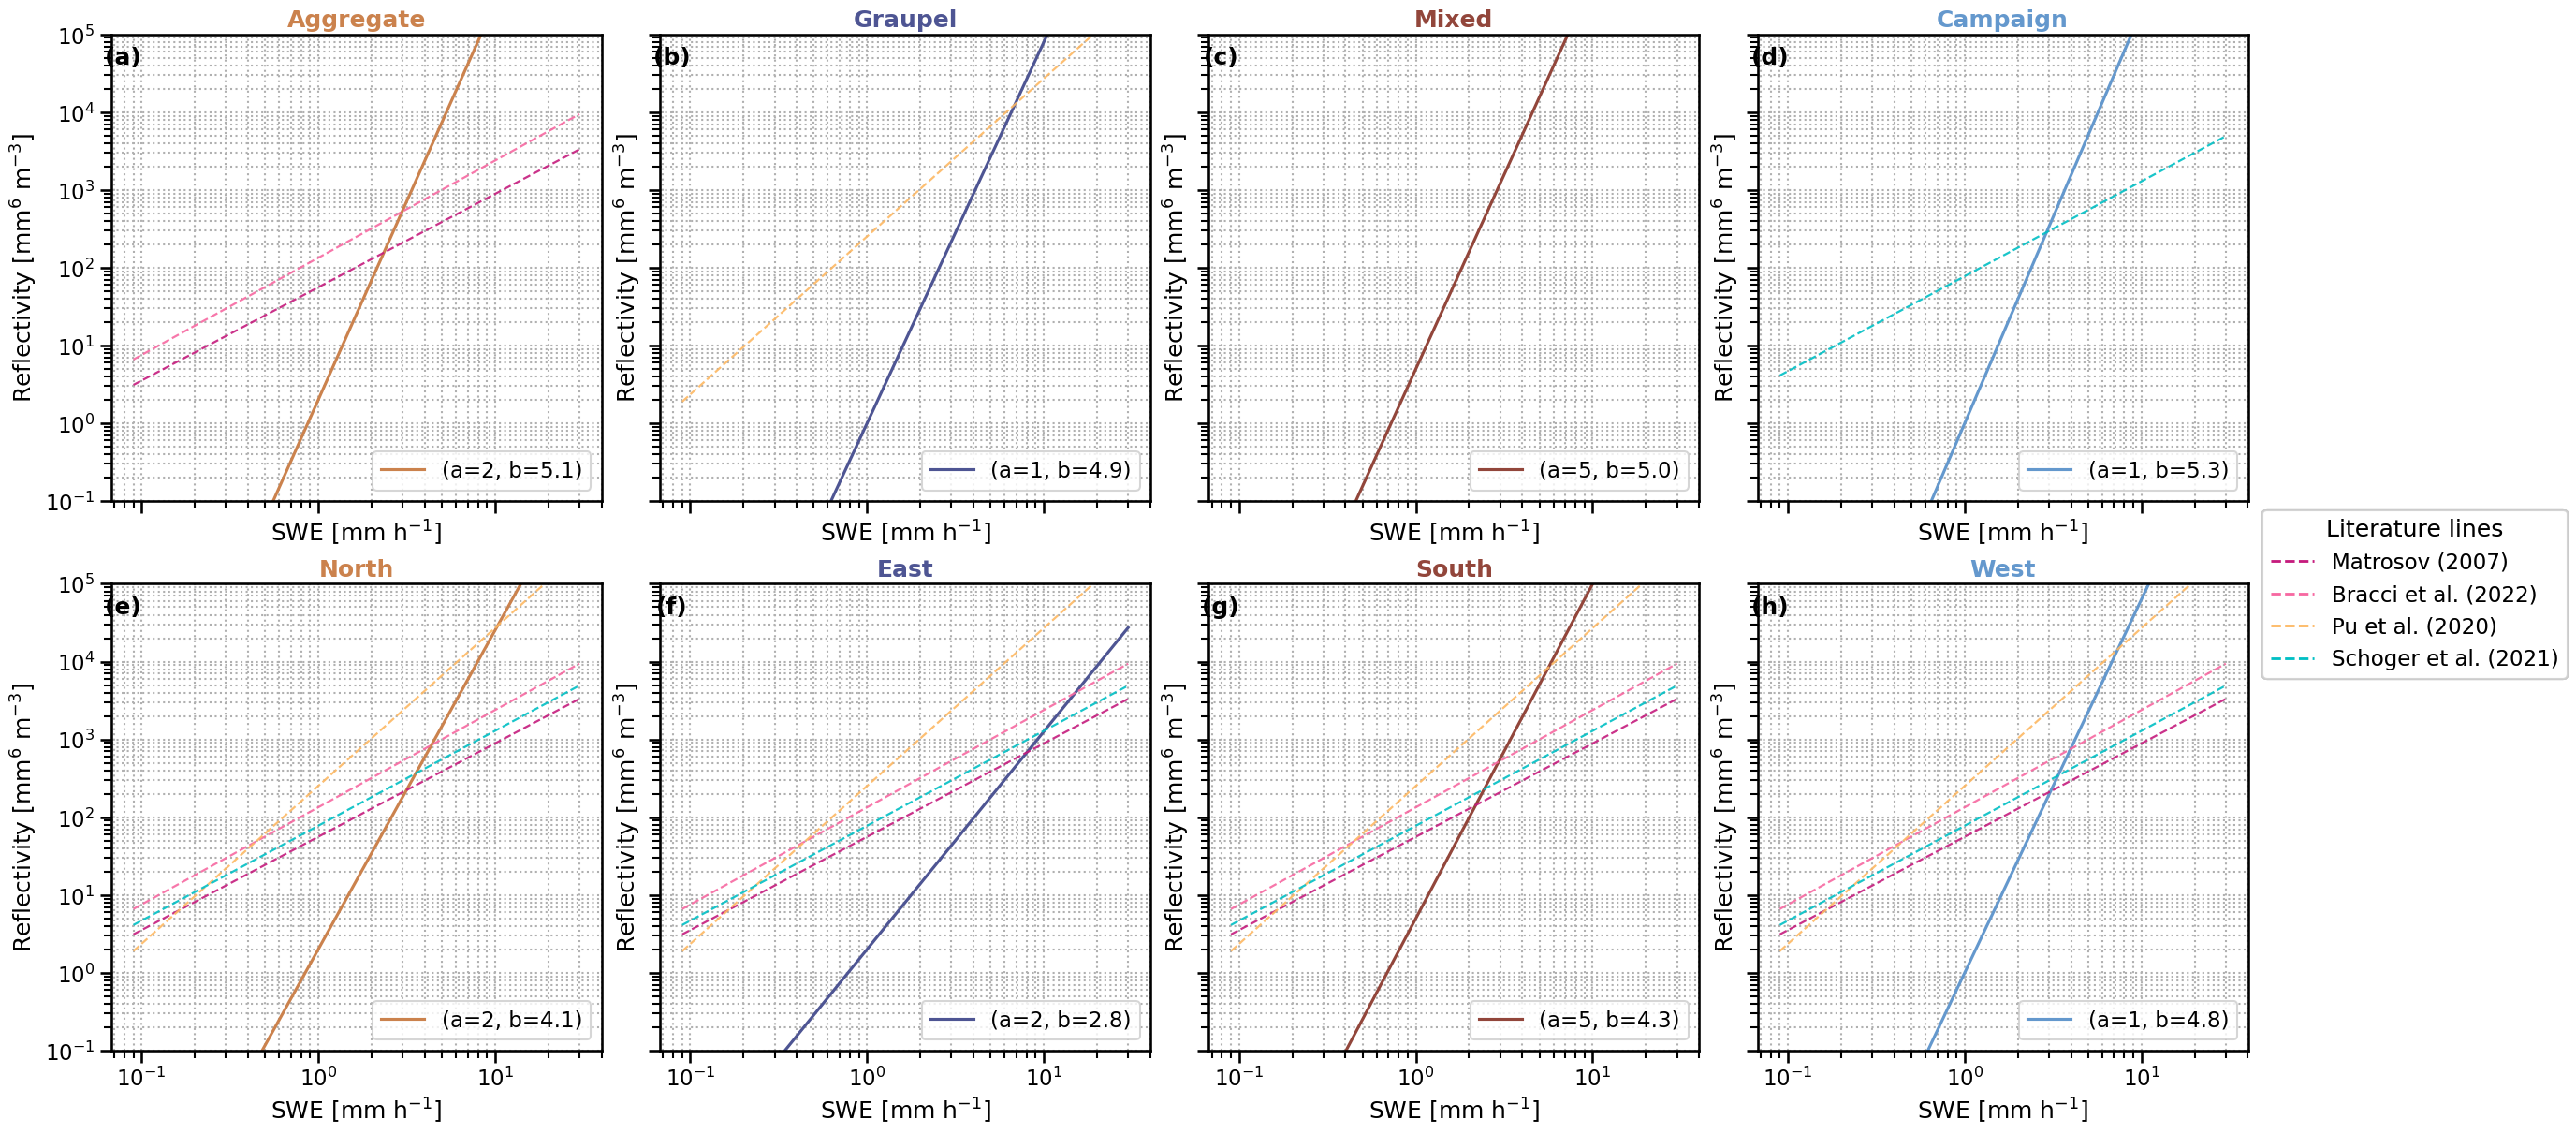

In [60]:
fig, axsm = plt.subplots(2, 4, figsize=(24,12), sharex=True, sharey=True, constrained_layout=True)
rows = [
    ["aggregate", "graupel", "mixed", "campaign", ],
    ['North', 'East', 'South', 'West']
]

row_cfg = {
    0: {# first row
        "main": ("snowflake_class", "-"),
        "extra": [("high_precipitation", "-."),
                  ("low_precipitation", ":")]},
    1: {# second row
        "main": ("wind_direction_sector", "-"),
        "extra": [("high_precipitation", "-."),
                  ("low_precipitation", ":")]},
}

custom_c = [LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(1),
                 LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(4),
                 LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(2),
                 LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(5)]
# Generate lines
x_line = np.logspace(np.log10(0.09), np.log10(30), 300)
y_line = 56*x_line**1.2

# 1-1 line
x= np.linspace(0,50, 100)
y=x
for r, row_cats in enumerate(rows):
        for c, class_key in enumerate(row_cats):
                ax = axsm[r, c]
                i = r*4 + c # index for fig label

                ax.text(0.025, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
                ax.grid(True, ls=":", which='both')
                ax.set_xscale('log')
                ax.set_yscale('log')
                ax.set(xlabel="SWE [mm h$^{-1}$]", ylabel="Reflectivity [mm${^6}$ m$^{-3}]$")
                ax.set_title(f"{class_key}".title(), fontweight='bold', color=custom_c[c])
                ax.set_ylim([10**(-1), 10**5])


                cfg = row_cfg[r]
                main_name, main_ls = cfg["main"]
                a_val, b_val = rmse_ab[main_name][60][class_key]
                label_name = main_name.replace("_", " ").title()
                y_line = a_val * x_line**b_val

                ax.plot(x_line, y_line, label=f"(a={a_val}, b={b_val})", color=custom_c[c], linestyle=main_ls)

                # # precipitation relations
                # for name, ls in cfg["extra"]:
                #         a_val, b_val = rmse_ab[name][class_key]
                #         label_name = name.replace("_", " ").title()
                #         y_line = a_val * x_line**b_val
                #         ax.plot(x_line, y_line, label=f"{label_name}: (a={a_val}, b={b_val})", color=custom_c[c], linestyle=ls)
                ax.legend(loc='lower right')
              

                if r == 0:
                        category_set = ("aggregate", "graupel", "mixed", "campaign")
                elif r== 1:
                        category_set = ('North', 'East', 'South', 'West')
                # all literature lines
                fct.plot_literature_lines(ax, class_key, category_set, x_line)
                
                lit_handles = [
                        Line2D(
                                [0], [0],
                                color=box["color"],
                                linestyle="--",
                                linewidth=2,
                                label=box["label"]
                        )
                        for box in fct.LITERATURE_BOXES.values()
                        ]

                fig.legend(
                        handles=lit_handles,
                        loc='upper left',
                        bbox_to_anchor=(1.0, 0.56),   # adjust as needed
                        frameon=True,
                        title=r"Literature lines"
                        )
                
# plt.savefig(FIG_DIR + "figA1.png", format='png', bbox_inches='tight', transparent=True,dpi=300)


In [59]:
fct.LITERATURE_BOXES.keys()

dict_keys(['A', 'B', 'C', 'D'])

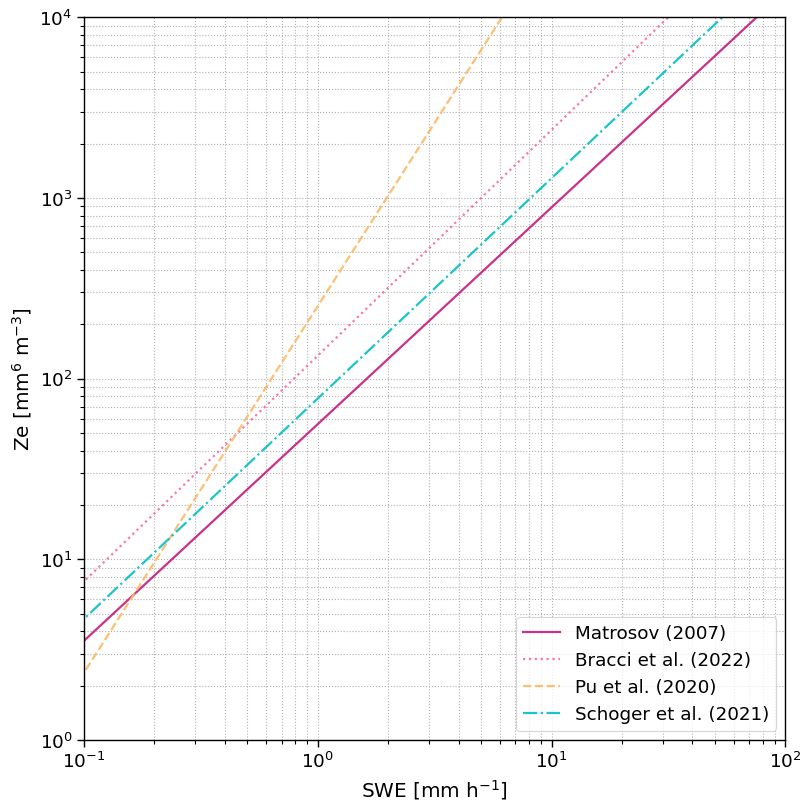

In [60]:
fig, ax = plt.subplots(1,1, figsize=(8,8), sharex=True, sharey=True, constrained_layout=True)
ax.grid(True, ls=":", which='both')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set(xlabel="SWE [mm h$^{-1}$]", ylabel="Ze [mm${^6}$ m$^{-3}]$")
# ax.set_title(f"{class_key}".title(), fontweight='bold', color=custom_c[c])
ax.set_ylim([1, 10**4])
ax.set_xlim([10**(-1), 10**2])

x_line = np.logspace(np.log10(0.09), np.log10(100), 300)
# for sf_class, ls in zip(snowflake_classes[:2], ["-", "-"] ):
#     a_val, b_val = rmse_ab['snowflake_class'][60][sf_class]
#     y_line = a_val * x_line**b_val

#     ax.plot(x_line, y_line, label=f"{sf_class}".title(), color=fct.custom_colors[sf_class], linestyle=ls)

for lit_id, ls in zip(fct.LITERATURE_BOXES.keys(), ['solid', 'dotted', 'dashed', 'dashdot']):
    lit = fct.LITERATURE_BOXES[lit_id]
    a = lit["a"]
    b = lit["b"]
    color = lit["color"]
    label = lit["label"]

    y = a * x_line**b

    ax.plot(
                x_line, y,
                color=color,
                linestyle=ls,
                linewidth=1.6,
                alpha=0.9,
                label=label
            )
ax.legend(loc='lower right')
plt.savefig(FIG_DIR + "Ze_S_literature.png", format='png', bbox_inches='tight', transparent=True,dpi=300)


## RMSE Literature

In [61]:
precip_event = 'campaign'
threshold = 60
xval = sf_class_dict[threshold][precip_event]['rate_mm_h']
for name in ['Matrosov_aggregate_400_mm_h', 'Bracci_aggregate_400_mm_h', 'Pu_graupel_400_mm_h', 'Schoger_400_mm_h']:
    yval = sf_class_dict[threshold][precip_event][name]
    mask = (
        (xval > 0) &
        (yval > 0) &
        np.isfinite(xval) &
        np.isfinite(yval)
    )
    xval = xval[mask]
    yval = yval[mask]

    log_x = np.log10(xval)
    log_y = np.log10(yval)

    err = log_y - log_x
    _rmse = np.sqrt(np.nanmean(err**2))

    print(name, _rmse.round(4))

Matrosov_aggregate_400_mm_h 0.6943
Bracci_aggregate_400_mm_h 0.8599
Pu_graupel_400_mm_h 0.799
Schoger_400_mm_h 0.7469


In [62]:
precip_event = 'campaign'
for thresh in [60, 70, 80]:
    rate = sf_class_dict[thresh][precip_event]['rate_mm_h']
    rate = rate.reindex(time_index).fillna(0)
    series_obs = rate*delta_h
    series_ret = rmse_series[thresh]["habit"]

    mask = (
            (series_obs > 0) &
            (series_ret > 0) &
            np.isfinite(series_obs) &
            np.isfinite(series_ret)
        )
    series_obs = series_obs[mask]
    series_ret = series_ret[mask]

    log_x = np.log10(series_obs)
    log_y = np.log10(series_ret)

    err = log_y - log_x
    _rmse = np.sqrt(np.nanmean(err**2))

    print(_rmse.round(4))

0.4083
0.4087
0.4097


In [63]:
rate = sf_class_dict[thresh][precip_event]['rate_mm_h']
rate = rate.reindex(time_index).fillna(0)
series_obs = rate*delta_h
series_ret = rmse_wind_series[threshold]["wind"]

mask = (
            (series_obs > 0) &
            (series_ret > 0) &
            np.isfinite(series_obs) &
            np.isfinite(series_ret)
        )
series_obs = series_obs[mask]
series_ret = series_ret[mask]

log_x = np.log10(series_obs)
log_y = np.log10(series_ret)

err = log_y - log_x
_rmse = np.sqrt(np.nanmean(err**2))

print(_rmse.round(4))


0.4058


In [64]:
# ret =rmse_series[80]['habit'].cumsum().fillna(method="ffill")
# ret = rmse_campaign_series[80]['campaign'].cumsum().fillna(method="ffill")
# ret = rmse_wind_series[60]['wind'].cumsum().fillna(method="ffill")
ret = err_cum_campaign_series[60]['campaign'].cumsum().fillna(method="ffill")
ret[-1].round(1)

np.float64(76.4)

In [65]:
precip_event = 'campaign'
rate = sf_class_dict[60][precip_event]['rate_mm_h']
rate = rate.reindex(time_index).fillna(0)
series = rate*delta_h
obs = series.reindex(time_index)
obs = obs.fillna(0)   # correct for rates / increments
cum_obs = obs.cumsum()
cum_obs = cum_obs - cum_obs.iloc[0]
len(cum_obs), cum_obs[-1].round(1)

(536, np.float64(76.3))

In [66]:
series = rmse_campaign_series[60][precip_event]
ret = series.reindex(time_index)
ret = ret.fillna(0)   # correct for rates / increments
cum_ret = ret.cumsum()
cum_ret = cum_ret - cum_ret.iloc[0]
len(cum_ret), cum_ret[-1].round(1), ((cum_ret[-1]-cum_obs[-1])/cum_obs[-1]*100).round(1)

(536, np.float64(108.4), np.float64(42.0))

In [67]:
cum_obs_div = cum_obs.loc["2023-03-11":"2023-03-12 00:00"] - cum_obs.loc["2023-03-11":"2023-03-12 00:00"].iloc[0]
cum_ret_div = cum_ret.loc["2023-03-11":"2023-03-12 00:00"] - cum_ret.loc["2023-03-11":"2023-03-12 00:00"].iloc[0]

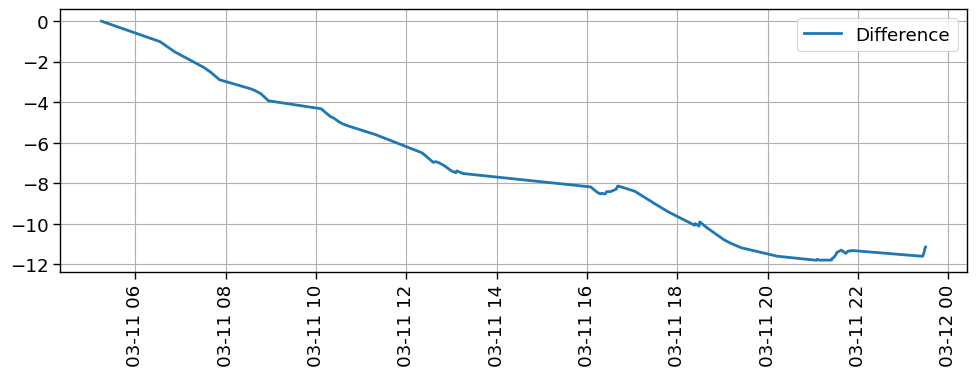

In [68]:
fig, ax = plt.subplots(figsize=(10,4))

# ax.plot(cum_obs, label='Observed')
# ax.plot(cum_ret, label="Retrieved")
# ax.plot(cum_obs-cum_ret, label="Difference")
ax.plot(cum_obs_div-cum_ret_div, label="Difference")
# ax.xaxis.set_major_locator(DayLocator(interval=1))
# ax.xaxis.set_major_formatter(DateFormatter('%Y-%m-%d'))
# ax.set_xlim([pd.Timestamp("'2023-03-09' 00:00:00"), pd.Timestamp(f"'2023-03-10' 23:00:00")])

plt.setp(ax.get_xticklabels(), rotation=90)

ax.grid(True)
ax.legend()

plt.tight_layout()


In [69]:
diff = (cum_obs-cum_ret)
# threshold = 8 #mm
start_date = diff[diff.abs() > 12].index.min()
start_date

Timestamp('2023-03-09 22:41:00')

In [70]:
abs(diff.loc['2023-03-09':'2023-03-10 12:00']).min()

np.float64(9.33787983092926)

In [71]:
abs(diff.loc['2023-03-09':'2023-03-10 23:59']).idxmax()

Timestamp('2023-03-10 22:30:00')

In [72]:
abs(diff.loc['2023-03-11':'2023-03-12 00:00']).min()

np.float64(14.82707355282409)

In [73]:
high_deviation_day = sf_class_dict[60]['campaign'][['Geonor','air_temperature', 'wind_direction','wind_speed','snowflake_class_name_60']].loc['2023-03-11':'2023-03-12 00:00']

<Axes: xlabel='time'>

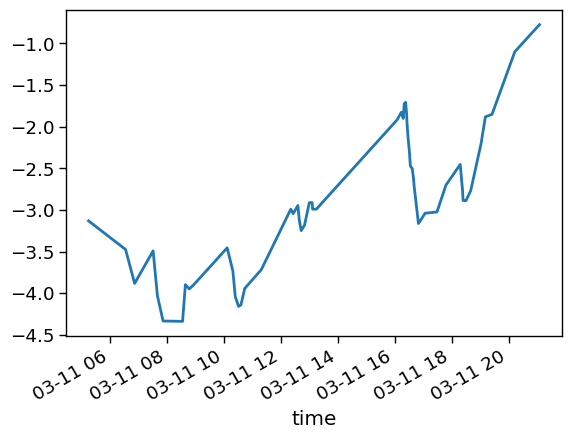

In [74]:
high_deviation_day['air_temperature'].dropna().plot()#.min()

In [75]:
len(sf_class_dict[60]['aggregate'][['Geonor','air_temperature', 'wind_direction','wind_speed','snowflake_class_name_60']].loc['2023-03-11':'2023-03-12 00:00'])

8

In [76]:
len(sf_class_dict[60]['graupel'][['Geonor','air_temperature', 'wind_direction','wind_speed','snowflake_class_name_60']].loc['2023-03-11':'2023-03-12 00:00'])

56

In [77]:
len(sf_class_dict[60]['mixed'][['Geonor','air_temperature', 'wind_direction','wind_speed','snowflake_class_name_60']].loc['2023-03-11':'2023-03-12 00:00'])

11

In [78]:
len(sf_class_dict[60]['campaign'][['Geonor','air_temperature', 'wind_direction','wind_speed','snowflake_class_name_60']].loc['2023-03-11':'2023-03-12 00:00'])

75

In [79]:
df_err_cum['snowflake_class'][60]['campaign'].min().min(), df_err_cum['snowflake_class'][60]['campaign'].max().max()

(np.float64(-58.450007615502884), np.float64(26441.744967970575))

In [80]:
counts.keys()

dict_keys(['snowflake_class', 'high_precipitation', 'low_precipitation', 'wind_direction_sector'])

In [81]:
df_rmse['snowflake_class'][60]['campaign'].at[err_cum_ab['snowflake_class'][60]['campaign']].round(4)

np.float64(0.4401)

## Plot literature scatter

KeyError: 'aggregate'

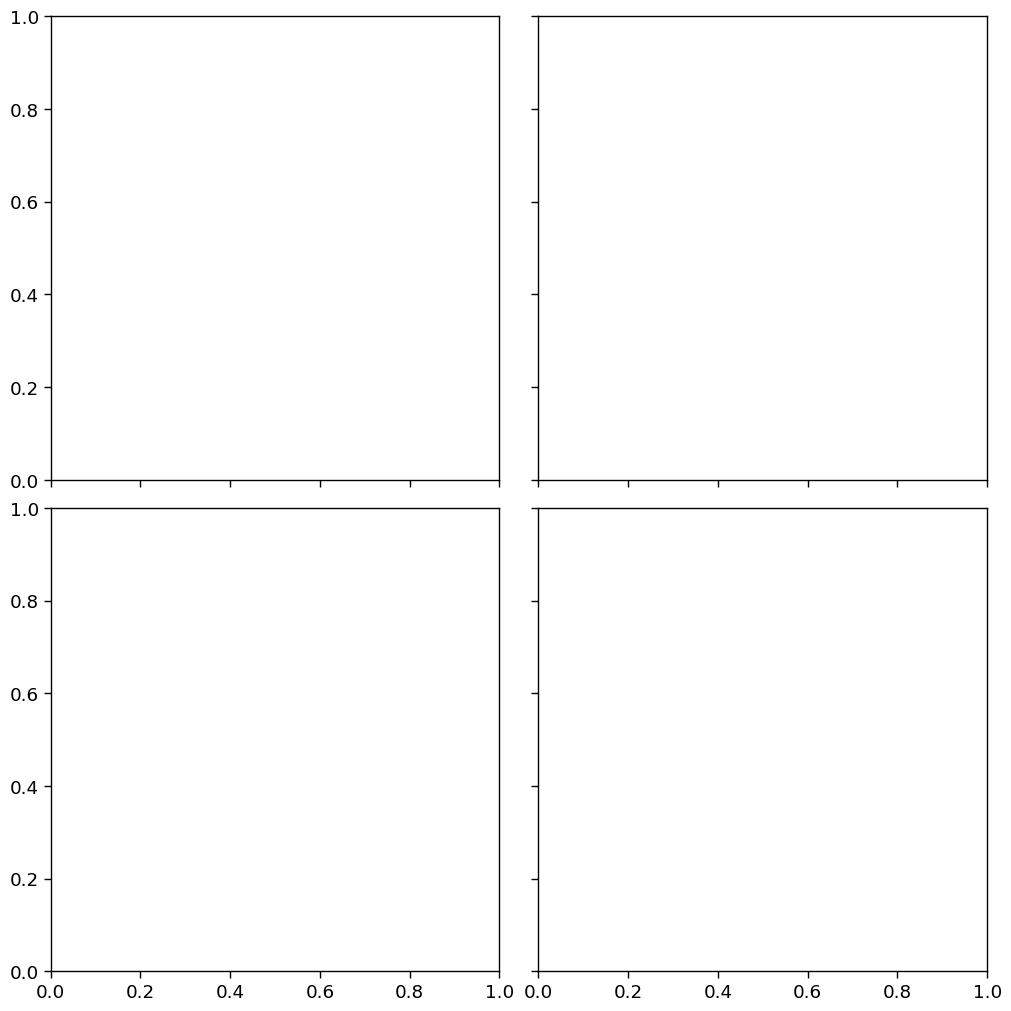

In [82]:
fct.plt_precip_scatter_literature(sf_class_dict, )
# plt.savefig(FIG_DIR + f"SWE_obs_vs_SWE_lit_precip_event_{site}_20230219_20230313_60percent.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:

for habit in ['aggregate', 'graupel', 'mixed', 'campaign']:
    print(habit, rmse_ab['snowflake_class'][habit], 
          df_rmse['snowflake_class'][habit].loc[rmse_ab['snowflake_class'][habit]].round(4),
          counts['snowflake_class'][habit])

KeyError: 'aggregate'

In [ ]:
for wd_sector in rmse_ab['wind_direction_sector'].keys():
    print(wd_sector, rmse_ab['wind_direction_sector'][wd_sector], 
          df_rmse['wind_direction_sector'][wd_sector].loc[rmse_ab['wind_direction_sector'][wd_sector]].round(4),
          counts['wind_direction_sector'][wd_sector])

In [ ]:
fig, axs = plt.subplots(2,2, figsize=(12,12), sharex=True, sharey=True, constrained_layout=True)

for (i, ax), class_key in zip(enumerate(axs.flatten()), ['aggregate', 'graupel', 'mixed', 'campaign']):
    SWE_obs = sf_class_dict[class_key]['rate_mm_h'].values
    # keep only finit values
    SWE_obs = SWE_obs[np.isfinite(SWE_obs)]
    # calculate quantiles
    q = np.percentile(SWE_obs, [25, 50, 75])
    iqr = q[2] - q[0]

    ax.hist(SWE_obs, bins=np.arange(0., 14.1,0.5), color=fct.custom_colors[class_key], edgecolor="grey", alpha=0.75)
    # for swe in q:
    #     ax.axvline(swe, color="k", ls="--", alpha=0.4)
    ax.axvline(q[1], color="k", ls="--", alpha=0.4)
    ax.text(q[1], ax.get_ylim()[1]*0.9, f"median = {q[1].round(2)}", color="k", alpha=0.4)

    ax.grid(True, ls=':')

    ax.set_title(f"{class_key}".title(), fontweight='bold', color=fct.custom_colors[class_key])
    ax.text(0.05, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment="center", verticalalignment='center', transform = ax.transAxes)
    

for i in range(2):
    axs[i, 0].set_ylabel("Number of precipitation events", )#fontsize=20)
    axs[1, i].set_xlabel("Geonor [mm h$^{{-1}}$]",)# fontsize=20)

# plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars


In [ ]:
# geonor = (sf_class_dict['campaign']['rate_mm_h']*delta_h).cumsum().fillna(method="ffill")[-1]
# retrieved = rmse_series['habit'].cumsum().fillna(method="ffill")[-1]
# # retrieved = (sf_class_dict['campaign']['Schoger_400_mm_h']*delta_h).cumsum().fillna(method="ffill")[-1]
# (((retrieved-geonor)/geonor)*100).round(1)

In [ ]:
Ze_400 = ds_23['Ze_400m']

In [ ]:
precip = {"high_precipitation": heavy_precip, "low_precipitation":low_precip}
fig, axsm = plt.subplots(2,4, figsize=(24,12), sharex=True, constrained_layout=True)

rows = [['aggregate', 'graupel', 'mixed', 'campaign'],['aggregate', 'graupel', 'mixed', 'campaign']]


for (r, row_cats), (pp_key, pp) in zip(enumerate(rows), precip.items()):
        
        for c, class_key in enumerate(row_cats):
            ax = axsm[r, c]
            i = r*4 + c # index for fig label

            ax.text(0.025, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
            ax.grid(True, ls=":")
            # ax.set_xscale('log')
            # ax.set_yscale('log')
            # ax.set(xlabel=, ylabel="Number of minutes")
            pp_key = pp_key.replace("_", " ").title()
            ax.set_title(f"{class_key} - {pp_key}".title(), fontweight='bold', color=custom_c[c])
            # ax.set_ylim([10**(-1), 10**5])

            Ze_400_obs = fct.get_ds_in_precip_event(pp[class_key], Ze_400)
            # keep only finit values
            Ze_400_obs = Ze_400_obs[np.isfinite(Ze_400_obs)]
            # calculate quantiles
            q = np.percentile(Ze_400_obs, [25, 50, 75])
            iqr = q[2] - q[0]
            ax.hist(Ze_400_obs, bins=np.arange(-10, 35,1), color=fct.custom_colors[class_key], edgecolor="grey", alpha=0.75)

            ax.axvline(q[1], color="k", ls="--", alpha=0.4)
            ax.text(q[1], ax.get_ylim()[1]*0.9, f"median = {q[1].round(2)} dBZ", color="k", alpha=0.4, horizontalalignment='center', verticalalignment='bottom')

            if r == 0:
                ax.set_ylim(0,15)
                
            elif r == 1:
                 ax.set_ylim(0, 210)
                 ax.set_xlabel("Reflectivity at 400m [dBZ]")
            if c == 0:
                 ax.set_ylabel("Number of minutes")
   

In [ ]:
category = ['aggregate', 'graupel', 'mixed', 'campaign']

In [ ]:
fct.plt_scatter_SWEobs_SWEret_4x4(rmse_ab['snowflake_class'], df_rmse['snowflake_class'], sf_class_dict, ['aggregate', 'graupel', 'mixed', 'campaign'])

In [ ]:
fct.plt_scatter_SWEobs_SWEret_4x4(rmse_ab['wind_direction_sector'], df_rmse['wind_direction_sector'], wd_sector_dict, ['North', 'East', 'South', 'West'])

In [ ]:
event_duration = (sf_class_dict['campaign']['delta_h']*60) # minutes
fig, ax = plt.subplots(1,1, figsize=(7,5))
ax.hist(event_duration, bins=np.arange(0, 60,1), color=fct.custom_colors['campaign'], edgecolor="grey", alpha=0.75)

q = np.percentile(Ze_400_obs, [25, 50, 75])
iqr = q[2] - q[0]

ax.axvline(q[1], color="k", ls="--", alpha=0.4)
ax.text(q[1], ax.get_ylim()[1]*0.9, f"median = {q[1].round(2)} minutes", color="k", alpha=0.4, horizontalalignment='center', verticalalignment='bottom')
ax.grid(True, ls=":")
ax.set_xlabel("Precipitation event duration")
ax.set_ylabel("Number of events")
ax.set_xlim([0, 61])

In [ ]:
precip = sf_class_dict['campaign']['rate_mm_h'] # mm/h


# remove NaNs
mask = np.isfinite(event_duration) & np.isfinite(precip) & (event_duration >0) & (precip>0)
x = event_duration[mask]
y = precip[mask]

x_bins = np.arange(x.min(), x.max())
y_bins = np.logspace(np.log10(y.min()), np.log10(y.max()), 60)
H, xedges, yedges = np.histogram2d(x, y, bins=[x_bins, y_bins])

# --- Discrete levels for colorbar ---
levels = [0, 1, 2, 3, 4, 5, 10, 15, 20, 50]   # ← adjust to your data density
cmap = cm.managua
## extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]
# force the first color entry to be white
cmaplist[0] = (255,255,255, 0.9)
# create the new map
cmap = LinearSegmentedColormap.from_list(
    'Custom cmap', cmaplist, len(levels))
norm = BoundaryNorm(levels, cmap.N, clip=True)

fig, ax = plt.subplots(figsize=(7,6))
# h = ax.hist2d(x, y, bins=[50,50], cmap=custom_cmap)
pcm = ax.pcolormesh(xedges, yedges, H.T, cmap=cmap, norm=norm, shading='auto', )

cbar = plt.colorbar(pcm, ax=ax, extend='max')
cbar.set_label("Number of events per bin")

ax.set_xlabel("Event duration [min]")
ax.set_ylabel("Precipiation rate [mm h$^{-1}$]")
ax.set_yscale('log')
ax.set_xscale('log')
ax.grid(ls=":", which='both')


In [ ]:
precip = sf_class_dict['campaign']['rate_mm_h']
flake_D = sf_class_dict['campaign']['flake_Dmax']

In [ ]:
# ----------------------------
# Figure
# ----------------------------
fig, axs = plt.subplots(1,1, figsize=(6,6), sharex=True, sharey=True, constrained_layout=True)

sc = axs.scatter(precip,flake_D, color=fct.custom_colors['campaign'], s=15, alpha=0.7)

# # plot 1:1 line
# x_line = np.linspace(0.01, 40, 100)
# axs.plot(x_line, x_line, linestyle='--', color='darkgrey', lw=1)

axs.set_xscale('log')
axs.set_yscale('log')
axs.grid(True, ls=':', which='both')
axs.set(xlabel="Precipitation rate [mm h$^{-1}$]", ylabel="Flake $D_{max}$ [mm]")

# fixed limits (important for visiual stability)
# axs.set_xlim(0.05, 40)
# axs.set_ylim(0.05, 40)

title = axs.set_title("all", fontweight='bold', color=fct.custom_colors['campaign'])

# dynamic annotation box


#### The following plots were for a presentation with white gridlines and text

In [ ]:
# Best (a,b) from RMSE extraction
a_best, b_best = rmse_ab['snowflake_class']['graupel']
save_path = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/animation/ab_ensemble_rmse_b3.2_graupel.mp4"
save_path_gif = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/animation/ab_ensemble_rmse_b3.2_graupel.gif"
fps = 15 # presentation quality (15-24 fps range)

# ----------------------------
# Data
# ----------------------------
x_obs = sf_class_dict['graupel']['rate_mm_h']  # SWE_obs
# SWE_retrieved is accessed dynamically per (a,b)

# ----------------------------
# Precompute RMSE lookup
# ----------------------------
rmse_map = df_rmse['snowflake_class']['graupel']  # DataFrame indexed by a,b
# assumes index=a, columns=b 

# ----------------------------
# Build frame sequence (stop at minimum RMSE)
# ----------------------------
frames = []
stop = False
for a in a_range[::-1]: #np.arange(30,40,10):#
    a = int(a)
    for b in np.arange(3.2, 3.3,0.1):#b_range:
        b = b.round(2)
        frames.append((a, b))
        if a == a_best and np.isclose(b, b_best):
            stop = True
            break
    if stop:
        break

print(f"Total frames: {len(frames)}")
# ----------------------------
# Figure
# ----------------------------
fig, axs = plt.subplots(1,1, figsize=(6,6), sharex=True, sharey=True, constrained_layout=True)

sc = axs.scatter([],[], color=fct.custom_colors['graupel'], s=15, alpha=0.7)

# plot 1:1 line
x_line = np.linspace(0.01, 40, 100)
axs.plot(x_line, x_line, linestyle='--', color='darkgrey', lw=1)

axs.set_xscale('log')
axs.set_yscale('log')
axs.grid(True, ls=':', which='both')
axs.set(xlabel="SWE$_{obs}$ [mm h$^{-1}$]", ylabel="SWE$_{retrieved}$ [mm h$^{-1}$]")

# fixed limits (important for visiual stability)
axs.set_xlim(0.05, 40)
axs.set_ylim(0.05, 40)

title = axs.set_title("", fontweight='bold', color=fct.custom_colors['graupel'])

# dynamic annotation box

# base position
x0, y0 = 0.02, 0.98
dy = 0.06 # vertical spacing in axses coords

# a-line
text_a = axs.text(x0, y0, "", transform=axs.transAxes, va='top', ha='left', fontsize=11, color='cyan', )#bbox=dict(boxstyle="round", fc="white", ec="0.5", alpha=0.9))

# b-ine
text_b = axs.text(x0, y0-dy, "", transform=axs.transAxes, va='top', ha='left', fontsize=11, color='magenta')

# rmse-line
text_rmse = axs.text(x0, y0-2*dy, "", transform=axs.transAxes, va='top', ha='left', fontsize=11, color='black')
# ----------------------------
# Animation update function
# ----------------------------
def update(frame_idx):
    a, b = frames[frame_idx]

    y_ret = sf_class_dict['graupel'][f"S_{a}_{b}_400_mm_h"]

    # update scatter
    sc.set_offsets(np.c_[x_obs.values, y_ret.values])

    # RMSE value
    try:
        rmse_val = rmse_map.loc[a, b]
    except:
        rmse_val = np.nan

    # update title
    title.set_text(f"Graupel — a = {a},  b = {b}")

    # update annotation
    # text_box.set_text(
    #     f"a = {a}\n"
    #     f"b = {b:.2f}\n"
    #     f"RMSE = {rmse_val:.4f}"
    # )
    text_a.set_text(f"a = {a}")
    text_b.set_text(f"b = {b:.2f}")
    text_rmse.set_text(f"RMSE = {rmse_val:.4f}")

    return sc, title, text_a, text_b, text_rmse


# # ----------------------------
# # Build animation
# # ----------------------------
# anim = FuncAnimation(fig, update, frames=len(frames), interval=1000/fps, blit=False)

# # ----------------------------
# # Save MP4
# # ----------------------------
# writer = FFMpegWriter(fps=fps, bitrate=1800)
# anim.save(save_path, writer=writer)

# writer = PillowWriter(fps=fps)
# anim.save(save_path_gif, writer=writer)
# plt.close(fig)

# print(f"Saved animation to:\n{save_path}")

In [ ]:
# plt.rcParams['axes.labelcolor'] = 'white'
# plt.rcParams['xtick.color'] = 'white'
# plt.rcParams['ytick.color'] = 'white'
# plt.rcParams['axes.edgecolor'] = 'white' # If using dark background


# fig, ax = plt.subplots(1,1, figsize=(6,6), sharex=True, sharey=True, constrained_layout=True)
# class_key = 'graupel'
# a, b = rmse_ab['snowflake_class'][class_key]

# rmse_val = df_rmse['snowflake_class'][class_key].loc[a, b]
# x_obs = sf_class_dict[class_key]['rate_mm_h']
# y_ret = sf_class_dict[class_key][f"S_{a}_{b}_400_mm_h"]
# sc = ax.scatter(x_obs, y_ret, color=custom_colors[class_key], alpha=0.7, edgecolors=custom_colors[class_key])


        
# # plot 1:1 line
# x_line = np.linspace(0.01, 40, 100)
# ax.plot(x_line, x_line, linestyle='--', color='darkgrey', lw=1)

# ax.set_xscale('log')
# ax.set_yscale('log')
# ax.grid(True, ls=':', which='both')


# # fixed limits (important for visiual stability)
# ax.set_xlim(0.009, 40)
# ax.set_ylim(0.009, 40)
        

# title = ax.set_title("", fontweight='bold', color=custom_colors[class_key])
# class_key = class_key.replace("_", " ").title()
# title.set_text(f"{class_key} — a = {a},  b = {b}")

# # dynamic annotation box
# text_box = ax.text(0.02, 0.98, "", 
#                 transform=ax.transAxes, va='top', ha='left', fontsize=11, bbox=dict(boxstyle="round", fc="white", ec="0.5", alpha=0.9))

        
# # update annotation
# text_box.set_text(
#                 f"a = {a}\n"
#                 f"b = {b:.2f}\n"
#                 f"RMSE = {rmse_val:.4f}"
#             )

#     # for i in range(2):
# ax.set_ylabel("SWE$_{retrieved}$ [mm h$^{-1}$]", )#fontsize=20)
# ax.set_xlabel("SWE$_{obs}$ [mm h$^{-1}$]",)# fontsize=20)

# # plt.savefig(FIG_DIR + f"SWE_obs_vs_SWE_graupel_best_ab_{site}_20230219_20230313.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:
# fig, axs = plt.subplots(1, 1, figsize=(12,6), sharex=True, sharey=True, constrained_layout=True)

# cmap = cm.managua
# ## extract all colors from the colormap
# cmaplist = [cmap(i) for i in range(cmap.N)]
# custom_cmap = LinearSegmentedColormap.from_list(
# 'Custom cmap', cmaplist, 7)

# plt_cum(axs, sf_class_dict['all']['rate_mm_h']*delta_h, "Geonor", "white", "-")


# styles = [
#     ("habit", "--"),
#     # ("habit_high_precipitation", "-."),
#     # ("habit_low_precipitation", ":") 
# ]
# for i, (name, ls) in enumerate(styles):
#     plt_cum(axs, rmse_series[name], name.replace("_", " ").title(), custom_cmap(0), ls)
 

# date_form = DateFormatter("%Y-%m-%d")

# axs.xaxis.grid(which="both", ls=":")
# axs.yaxis.grid(which="both", ls=":")
# axs.tick_params(axis="x", labelrotation=0)
# plt.setp(axs.get_xticklabels(), horizontalalignment='center')
# axs.xaxis_date()
# axs.xaxis.set_major_formatter(date_form)
# axs.set_xlim([pd.Timestamp("'2023-02-19' 00:00:00"), pd.Timestamp(f"'2023-03-15' 00:00:00")])
# axs.set_ylabel("Precipitation [mm]")
# axs.set_ylim([0,90])

# axs.legend(loc='center left', bbox_to_anchor=(1.04, 0.5))
# # plt.tight_layout(rect=[0, 0, 0., 1])   # leave room for cbars
# # plt.savefig(FIG_DIR + f"campaign_accumulation_best_ab_habit_{site}_20230219_20230313.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:
# fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,6), sharex=True, sharey=True, constrained_layout=True)

# plt.rcParams['axes.labelcolor'] = 'white'
# plt.rcParams['xtick.color'] = 'white'
# plt.rcParams['ytick.color'] = 'white'
# plt.rcParams['axes.edgecolor'] = 'white' # If using dark background

#     # for (i, ax), 'graupel' in zip(enumerate(axs.flatten()), category):
# a_vals = df_rmse['snowflake_class']['graupel'].index.values
# b_vals = df_rmse['snowflake_class']['graupel'].columns.values

# a_edges = edges_from_centers(a_vals)
# b_edges = edges_from_centers(b_vals)

# A, B = np.meshgrid(df_rmse['snowflake_class']['graupel'].columns, df_rmse['snowflake_class']['graupel'].index)
# c = ax.pcolormesh(A, B, df_rmse['snowflake_class']['graupel'].values, vmin=0, vmax=1, 
#                       cmap=custom_cmap,shading="auto", edgecolors=(0, 0, 0, 0.2), linewidth=0.005, alpha=0.9)
        
#         # hightlight the cell with minimum RMSE/MAE
#         # index of min
#         # iy, ix = df_rmse['snowflake_class']['graupel'].stack().idxmin()
# iy, ix= np.unravel_index(np.nanargmin(df_rmse['snowflake_class']['graupel'].values), df_rmse['snowflake_class']['graupel'].shape)
# # rectangle edges
# x0 = b_edges[ix]
# y0 = a_edges[iy]
# width = b_edges[ix + 1] - b_edges[ix]
# height = a_edges[iy +1] - a_edges[iy] 
# ax.add_patch(Rectangle((x0, y0), width, height,
#                         fill=False, edgecolor="black", linewidth=3.5, zorder=9))
# ax.add_patch(Rectangle((x0, y0), width, height,
#                         fill=False, edgecolor="white", linewidth=2.5, zorder=10))

#         # Highlight literature boxes
# placement = get_lit_placement(["aggregate", "graupel", "mixed", "all"])

# for study_key in placement.get('graupel', []):
#             box = LITERATURE_BOXES[study_key]
#             draw_lit_box(ax, box, a_edges, b_edges)


  


# # Ticks & labels
# ax.set_title(f"{'graupel'} (counts={counts['snowflake_class']['graupel']})".title(), fontweight='bold', color=custom_colors['graupel'])
# # ax.text(0.05, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment="center", verticalalignment='center', transform = ax.transAxes,)


# ax.set_ylabel(r"$a$", fontsize=20, color='white')
# ax.set_xlabel(r"$b$", fontsize=20, color='white')

# LIT_BOXES = {"C": LITERATURE_BOXES["C"]}
# lit_handles = [
#     Patch(facecolor="none",
#           edgecolor=box["color"],
#           linewidth=2.5,
#           label=box["label"])
#     for box in LIT_BOXES.values()
# ]


# fig.legend(
#     handles=lit_handles,
#     loc='upper left',
#     bbox_to_anchor=(0.88, 0.28),  # tweak this
#     frameon=True,
#     title=r"Literature ($a$, $b$)"
# )

    

# plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars
# cax = fig.add_axes([0.9, 0.3 , 0.015, 0.45]) # left, bottom, width, height
# cb = fig.colorbar(c, cax=cax, orientation='vertical', label="Root Mean Square Error",spacing="proportional", extend="both")

# # plt.savefig(FIG_DIR + f"RMSE_graupel_ab_{site}_20230219_20230313.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

In [ ]:
# category = ['aggregate', 'graupel', 'mixed', 'all']
# custom_colors = {  
#                      category[0]: LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(1),  
#                      category[1]:LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(4),   
#                      category[2]: LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(2),
#                      category[3]: LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(5),
# }
    
    

# fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12,6), sharex=True, sharey=True, constrained_layout=True)
# axs = np.atleast_2d(axs)
# df = df_rmse['snowflake_class']
# for (i, ax), class_key in zip(enumerate(axs.flatten()), ['graupel', 'aggregate']):
#         a_vals = df[class_key].index.values
#         b_vals = df[class_key].columns.values

#         a_edges = edges_from_centers(a_vals)
#         b_edges = edges_from_centers(b_vals)

#         A, B = np.meshgrid(df[class_key].columns, df[class_key].index)
#         c = ax.pcolormesh(A, B, df[class_key].values, vmin=0, vmax=1, 
#                       cmap=custom_cmap,shading="auto", edgecolors=(0, 0, 0, 0.2), linewidth=0.005, alpha=0.9)
        
#         # hightlight the cell with minimum RMSE/MAE
#         # index of min
#         # iy, ix = df[class_key].stack().idxmin()
#         iy, ix= np.unravel_index(np.nanargmin(df[class_key].values), df[class_key].shape)
#         # rectangle edges
#         x0 = b_edges[ix]
#         y0 = a_edges[iy]
#         width = b_edges[ix + 1] - b_edges[ix]
#         height = a_edges[iy +1] - a_edges[iy] 
#         ax.add_patch(Rectangle((x0, y0), width, height,
#                         fill=False, edgecolor="black", linewidth=3.5, zorder=9))
#         ax.add_patch(Rectangle((x0, y0), width, height,
#                         fill=False, edgecolor="white", linewidth=2.5, zorder=10))

#         # Highlight literature boxes
#         placement = get_lit_placement(category)

#         for study_key in placement.get(class_key, []):
#             box = LITERATURE_BOXES[study_key]
#             draw_lit_box(ax, box, a_edges, b_edges)


  


#         # Ticks & labels
#         ax.set_title(f"{class_key} (counts={counts['snowflake_class'][class_key]})".title(), fontweight='bold', color=custom_colors[class_key])
#         ax.text(0.05, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment="center", verticalalignment='center', transform = ax.transAxes,)
#         ax.set_xlabel(r"$b$", fontsize=20, )

# axs.flatten()[0].set_ylabel(r"$a$", fontsize=20, )#color='white')
# #         axs[1, i].set_xlabel(r"$b$", fontsize=20, )#color='white')
# LIT_BOXES = {"A": LITERATURE_BOXES["A"], "B":LITERATURE_BOXES["B"], "C": LITERATURE_BOXES["C"]}
 
# lit_handles = [
#     Patch(facecolor="none",
#           edgecolor=box["color"],
#           linewidth=2.5,
#           label=box["label"])
#     for box in LIT_BOXES.values()
# ]


# fig.legend(
#     handles=lit_handles,
#     loc='upper left',
#     bbox_to_anchor=(0.88, 0.28),  # tweak this
#     frameon=True,
#     title=r"Literature ($a$, $b$)"
# )

    

# plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars
# cax = fig.add_axes([0.9, 0.3 , 0.015, 0.45]) # left, bottom, width, height
# cb = fig.colorbar(c, cax=cax, orientation='vertical', label="Root Mean Square",spacing="proportional", extend="both")

# # plt.savefig(FIG_DIR + f"RMSE_graupel_aggregate_ab_{site}_20230219_20230313.png", format='png', bbox_inches='tight', transparent=True,dpi=300)